# 03 · Metodi geometrici non lineari: Isomap (e poi UMAP) · FALCON H1

**Obiettivo.** Nel notebook 02 abbiamo descritto l'attività della popolazione con metodi
**lineari** (PCA, FA, GPFA). Tutti e tre fanno la stessa ipotesi: che i dati stiano in un
**sottospazio piatto**, come un foglio disteso. Qui togliamo questa ipotesi con i metodi della
famiglia "geometrica" (review, §4.1), che ricostruiscono il manifold guardando solo **chi è vicino
a chi**:

- **Isomap** (parte A, questo notebook): conserva le distanze misurate **lungo** il manifold;
- **UMAP** (parte B, §9, in breve): conserva i **vicini**, non le distanze.

Per Isomap le domande sono tre:

1. **Il manifold è curvo?** Misurare le distanze lungo il manifold, invece che in linea d'aria,
   descrive meglio i dati?
2. **Quante dimensioni servono** se si tiene conto della curvatura? È la distinzione tra dimensione
   *di embedding* (quella che vede la PCA) e dimensione *intrinseca* (review, §2.4; Jazayeri &
   Ostojic 2021).
3. **Le fasi del task si riconoscono meglio** nelle coordinate di Isomap che in quelle della PCA?

La pipeline:

```
spike_times ──(come nel 02: bin 20 ms, 160 canali attivi, σ = 50 ms, z-score)──► Z   12233 × 160

Z ──(§2: solo fasi di movimento, un bin ogni 5, PCA a 25)──────────────────────► X   ~1100 × 25

X ──(§3: Isomap = grafo dei vicini → distanze geodesiche → MDS)────────────────► coordinate Isomap

poi:  §4  che cosa si vede               §5  il manifold è curvo? (varianza residua + surrogati)
      §6  le fasi si riconoscono meglio? §7  analisi di sensibilità e alternative
      §8  riepilogo di Isomap            §9  parte B: UMAP in breve
```

Stessa sessione dei notebook 02 e 02_new (`held-in-calib`, `19250108T110520`), così i numeri
sono confrontabili.

**Tempo di esecuzione:** circa 6-7 minuti: le stime della GPFA del §7.2 e le ripetizioni di UMAP del §9.

## 0 · Setup

In [1]:
import os                                         # per impostare una variabile d'ambiente prima degli altri import
os.environ.setdefault("KMP_WARNINGS", "off")      # nasconde un messaggio innocuo di OpenMP che comparirebbe con UMAP (§9)
os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")  # numba (usato da UMAP) non carica una seconda copia di OpenMP: insieme a quella di scikit-learn il kernel a volte si blocca
import sys                                        # per aggiungere src/ ai percorsi in cui Python cerca i moduli
import warnings                                   # per nascondere avvisi innocui
from pathlib import Path                          # percorsi dei file, indipendenti dal sistema operativo

import numpy as np                                # array e algebra lineare
import pandas as pd                               # tabelle per i riepiloghi
import matplotlib.pyplot as plt                   # figure
from scipy.sparse.csgraph import shortest_path, connected_components  # percorsi più brevi su un grafo; pezzi separati di un grafo
from scipy.spatial.distance import pdist, squareform, cdist  # distanze a coppie; da "lista di coppie" a matrice; distanze tra due insiemi
from sklearn.decomposition import PCA             # PCA (pre-riduzione e confronto)
from sklearn.preprocessing import StandardScaler  # z-score colonna per colonna
from sklearn.neighbors import NearestNeighbors, kneighbors_graph, KNeighborsClassifier  # ricerca dei vicini; grafo dei vicini; classificatore "a vicini"
from sklearn.manifold import Isomap               # Isomap di scikit-learn, per verificare il nostro calcolo a mano
from sklearn.model_selection import GroupKFold    # cross-validation che tiene insieme i bin dello stesso trial
from sklearn.metrics import balanced_accuracy_score  # accuratezza che pesa allo stesso modo tutte le fasi
from sklearn.datasets import make_swiss_roll      # il "foglio arrotolato": esempio sintetico classico di manifold curvo

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # radice del progetto, da qualunque cartella parta il notebook
sys.path.insert(0, str(ROOT / "src"))             # rende importabile il pacchetto del progetto
from tesi_h1 import io                            # caricamento dei dati, fasi, colori (verificati passo per passo nel 02_new)

warnings.filterwarnings("ignore")                 # scikit-learn ed elephant stampano avvisi innocui (es. grafo con più pezzi)
FIGS = ROOT / "figures"                           # cartella delle figure in PNG
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})  # stesso stile grafico degli altri notebook

SESS = ROOT / "data/raw/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T110520.nwb"  # sessione analizzata

## 1 · I dati: gli stessi del notebook 02

Partiamo dagli stessi dati della PCA del notebook 02: bin da 20 ms, 160 canali attivi
(≥ 0.5 Hz), smoothing gaussiano con σ = 50 ms, z-score per canale. Nel 02_new ogni passo è stato
rifatto a mano e confrontato con le funzioni di `tesi_h1.io`, e coincideva: qui usiamo
direttamente le funzioni.

A ogni bin associamo due etichette, che **non** entrano mai nei metodi (sono tutti non
supervisionati) ma servono a valutarli:

- la **fase del task** in cui cade il bin (`Reach`, `Orient`, ...);
- il **trial** a cui appartiene.

In [2]:
s = io.load_session(SESS)                                   # conteggi a 20 ms, cinematica, fasi del task
ACTIVE = io.active_units(s, min_hz=0.5)                     # i 160 canali attivi
Z = StandardScaler().fit_transform(                         # z-score per canale...
    io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE].astype(float))  # ...dei firing rate smussati con σ = 50 ms
n_bins = s.n_bins                                           # numero di bin della sessione

def base_tag(tag):                                          # "Presentation3" -> "Presentation": un'etichetta per tutte le presentazioni
    return "Presentation" if tag.startswith("Presentation") else tag

phase = np.array([base_tag(p) for p in io.phase_per_bin(s)], dtype=object)  # fase di ogni bin ("" se nessuna fase lo copre)
trial = s.trial_num                                         # trial di ogni bin
MOV = np.isin(phase, io.MOVEMENT_PHASES)                    # vero per i bin che cadono in una fase di movimento

print(f"Z: {Z.shape[0]} bin × {Z.shape[1]} canali, {len(np.unique(trial))} trial")
print(f"Bin nelle fasi di movimento: {MOV.sum()} su {n_bins} ({MOV.mean() * 100:.0f}%)")
print(pd.Series(phase[MOV]).value_counts().reindex(io.MOVEMENT_PHASES).rename("bin per fase").to_frame().T.to_string())

Z: 12233 bin × 160 canali, 15 trial
Bin nelle fasi di movimento: 5507 su 12233 (45%)
              Reach  Orient  SnapTo  Shape  Grasp  Carry  Orient2  Release
bin per fase    958     757     291    464    621    971      854      591


## 2 · Il grafo dei vicini: quali dati dare a Isomap

### Perché la scelta dell'input è così importante

Isomap (e anche UMAP, nella parte B) comincia sempre allo stesso modo: ogni punto "dà la mano" ai
suoi **k punti più vicini** (qui k = 10). Tutto il resto del metodo è costruito su questa rete di
strette di mano. Scegliere i dati di input vuol dire quindi **scegliere chi finisce vicino a chi**.

Che cosa vogliamo? Che un istante di `Grasp` del trial 3 sia vicino a istanti di `Grasp` di
**altri** trial: solo così la rete collega le ripetizioni e descrive un manifold **comune**, non la
storia di un singolo trial.

Per ogni punto dividiamo i suoi 10 vicini in tre gruppi:

- **catena del tempo**: stesso trial ed entro 200 ms. È "sé stesso un attimo prima o dopo";
- **stessa fase, altro trial**: quello che vogliamo;
- **altro**: fase diversa, oppure stesso trial ma lontano nel tempo.

e confrontiamo quattro input possibili.

In [3]:
K_NN = 10                                                   # vicini per punto (la scelta si controlla al §7.1)
CHAIN_BINS = 10                                             # "catena del tempo": stesso trial ed entro 10 bin = 200 ms

def knn_index(Xp, k=K_NN, forbid=None):                     # indici dei k vicini di ogni punto (esclude il punto stesso)
    D = squareform(pdist(Xp))                               # matrice n × n delle distanze in linea d'aria
    np.fill_diagonal(D, np.inf)                             # un punto non è vicino di sé stesso
    if forbid is not None:                                  # coppie vietate (serve per la finestra di Theiler, §7.2)
        D[forbid] = np.inf
    return np.argpartition(D, k, axis=1)[:, :k]             # per ogni riga, le k colonne con la distanza più piccola

def neighbor_mix(nb, b, rows=None):                         # di che tipo sono i vicini: tre frazioni che sommano a 1
    tr_, ph_ = trial[b], phase[b]                           # trial e fase di ogni punto (b = bin di ciascun punto)
    chain = (tr_[nb] == tr_[:, None]) & (np.abs(b[nb] - b[:, None]) <= CHAIN_BINS)   # stesso trial, entro 200 ms
    good = ~chain & (ph_[nb] == ph_[:, None]) & (tr_[nb] != tr_[:, None])            # stessa fase, altro trial
    rows = np.ones(len(b), bool) if rows is None else rows  # su quali punti fare la media (tutti, o solo quelli di movimento)
    return {"catena del tempo": chain[rows].mean(), "stessa fase, altro trial": good[rows].mean(),
            "altro": 1 - chain[rows].mean() - good[rows].mean()}

def chance_good(b):                                         # la frazione "stessa fase, altro trial" se i vicini fossero scelti a caso
    ph_, tr_ = phase[b], trial[b]
    return np.mean([np.mean((ph_ == ph_[i]) & (tr_ != tr_[i])) for i in range(len(b))])

STEP = 5                                                    # un bin ogni 5 = uno ogni 100 ms
K_PCA = 25                                                  # dimensioni tenute dalla PCA (motivazione sotto)
bins_all = np.flatnonzero(MOV)                              # tutti i bin delle fasi di movimento (uno ogni 20 ms)
bins = bins_all[bins_all % STEP == 0]                       # quelli su una griglia regolare di 100 ms
pca_in = PCA(n_components=K_PCA).fit(Z[bins_all])           # PCA stimata su tutti i bin delle fasi di movimento
Z25 = pca_in.transform(Z)                                   # tutta la sessione proiettata sulle 25 direzioni
Zc = StandardScaler().fit_transform(s.spikes[:, ACTIVE].astype(float))  # conteggi grezzi z-scored, per il primo confronto

inputs = {                                                  # i quattro input: (dati di tutta la sessione, bin usati come punti)
    "conteggi grezzi, 160 canali": (Zc, bins_all),
    "smussati σ = 50 ms, 160 canali": (Z, bins_all),
    "smussati + PCA a 25": (Z25, bins_all),
    "smussati + PCA a 25, un bin ogni 5": (Z25, bins),
}
mix = {name: neighbor_mix(knn_index(Xf[b]), b) for name, (Xf, b) in inputs.items()}  # composizione dei vicini per ogni input
tab_mix = (pd.DataFrame(mix).T * 100).round(1)
tab_mix["punti"] = [len(b) for _, b in inputs.values()]
tab_mix["'stessa fase, altro trial' a caso"] = [round(chance_good(b) * 100, 1) for _, b in inputs.values()]
display(tab_mix)

,catena del tempo,"stessa fase, altro trial",altro,punti,"'stessa fase, altro trial' a caso"
"conteggi grezzi, 160 canali",1.1,16.4,82.5,5507,12.7
"smussati σ = 50 ms, 160 canali",95.1,1.9,3.0,5507,12.7
smussati + PCA a 25,87.5,4.6,7.9,5507,12.7
"smussati + PCA a 25, un bin ogni 5",20.4,27.1,52.5,1106,12.7


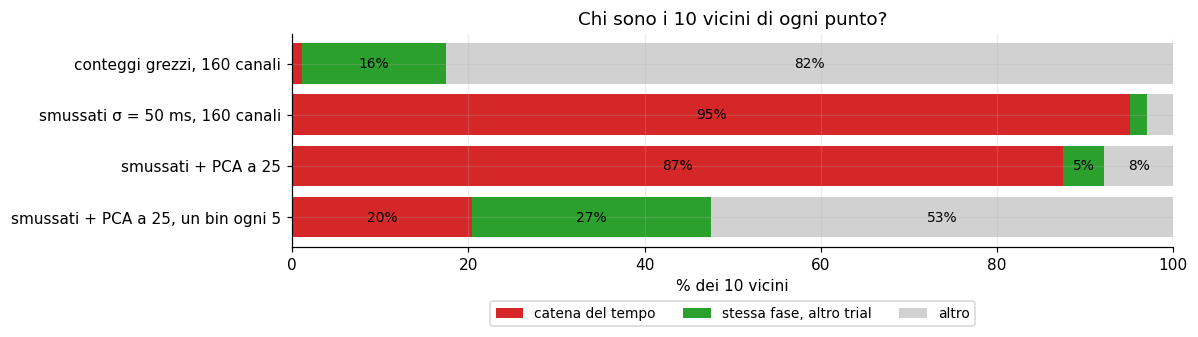

In [4]:
cats, cols = ["catena del tempo", "stessa fase, altro trial", "altro"], ["C3", "C2", "0.82"]
fig, ax = plt.subplots(figsize=(11, 3.3))
for i, m in enumerate(mix.values()):                        # una barra per input
    left = 0
    for c, col in zip(cats, cols):                          # i tre gruppi uno dopo l'altro, fino al 100%
        ax.barh(i, m[c] * 100, left=left, color=col, label=c if i == 0 else None)
        if m[c] > 0.04:                                     # scrive la percentuale solo se il pezzo è abbastanza largo
            ax.text(left + m[c] * 50, i, f"{m[c] * 100:.0f}%", ha="center", va="center", fontsize=9)
        left += m[c] * 100
ax.set_yticks(range(len(mix))); ax.set_yticklabels(list(mix)); ax.invert_yaxis()
ax.set(xlabel="% dei 10 vicini", xlim=(0, 100), title="Chi sono i 10 vicini di ogni punto?")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "03_neighbor_mix.png", bbox_inches="tight"); plt.show()

**Lettura.** Ci sono due trappole opposte.

1. **Conteggi grezzi: decide il rumore.** I vicini "stessa fase, altro trial" sono appena sopra il
   caso. È come confrontare pixel per pixel due foto molto sgranate: la differenza la fa la grana,
   non il soggetto.
2. **Dati smussati: la catena del tempo.** Lo smoothing fa sì che ogni bin sia quasi una copia di
   quello di 20 ms prima (i due contengono in gran parte gli stessi spike). Il vicino più vicino di
   ogni punto diventa "sé stesso un attimo prima": succede per quasi tutti i vicini. È come in un
   film: il fotogramma più simile a qualunque fotogramma è quello appena prima, e non si trova mai
   la stessa scena girata in un altro ciak. Su questa rete Isomap ricostruirebbe il **tempo dentro
   ogni trial**, non il manifold.

**La PCA a 25 dimensioni da sola non basta**: la catena resta. Il passo decisivo è **un bin ogni
5**: sparite le "copie", i vicini vanno cercati nelle altre ripetizioni, e quelli della stessa
fase in altri trial diventano circa il doppio del caso. Il sottocampionamento quindi non serve solo
alla velocità: serve soprattutto a evitare questa trappola.

### Le scelte per il resto del notebook

- **Solo i bin delle fasi di movimento**: ogni punto ha un'etichetta di fase e possiamo misurare
  quanto bene le fasi si separano. Ogni bin compare **una volta sola** (non usiamo le finestre da
  1 s del notebook 02, che si sovrappongono quando una fase dura meno di 1 s e creerebbero punti
  doppi a distanza zero).
- **PCA a 25 dimensioni prima di Isomap.** Toglie le direzioni in cui c'è quasi solo rumore
  indipendente tra canali. Non "raddrizza" il manifold: una strada curva su una cartina resta curva
  anche se si toglie l'altitudine. 25 è il numero di fattori scelto dalla cross-validation della
  GPFA nel notebook 02, quindi non lo scegliamo noi, ed è più grande delle dimensioni che ci
  aspettiamo di trovare: con 10 dimensioni Isomap non potrebbe mai rispondere "12".
- **Un bin ogni 5 (100 ms).**

Tutte e tre le scelte si controllano al §7.

In [5]:
X = Z25[bins]                                               # i punti su cui lavora Isomap: n × 25
ph, tr = phase[bins], trial[bins]                           # fase e trial di ciascun punto
print(f"X: {X.shape[0]} punti × {X.shape[1]} dimensioni")
print(f"Varianza dei bin di movimento tenuta dalle 25 componenti: {pca_in.explained_variance_ratio_.sum() * 100:.0f}%")

X: 1106 punti × 25 dimensioni
Varianza dei bin di movimento tenuta dalle 25 componenti: 38%


Le 25 componenti tengono circa un terzo della varianza. Non è poco: il resto è in gran parte il
rumore indipendente dei singoli canali che, nel notebook 02, spingeva il participation ratio a
~106.

## 3 · Isomap: che cosa fa

### L'idea

Isomap (Tenenbaum, de Silva & Langford 2000) è **una PCA che misura le distanze lungo il manifold
invece che in linea d'aria**. Tre passi:

1. **Grafo dei vicini.** Ogni punto viene collegato ai suoi k = 10 vicini più vicini: sono le
   "strade" tra punti che si trovano sicuramente sullo stesso pezzo di manifold.
2. **Distanze geodesiche.** La distanza tra due punti qualsiasi diventa la lunghezza del
   **percorso più breve lungo le strade**: la distanza "a piedi", non "in linea d'aria".
3. **MDS classico** (*multidimensional scaling*). Si cercano coordinate in d dimensioni in cui le
   distanze normali (in linea d'aria) riproducono il meglio possibile le distanze geodesiche. È lo
   stesso calcolo della PCA (autovalori e autovettori), fatto sulle distanze geodesiche.

Se al passo 3 si usassero le distanze in linea d'aria, il risultato sarebbe **esattamente la
PCA** (lo verifichiamo al §3.5). Tutta la differenza tra PCA e Isomap sta quindi nel modo di
misurare le distanze.

### Un esempio su dati sintetici: il foglio arrotolato

Prima dei dati veri vediamo che cosa fa Isomap su un manifold di cui conosciamo la forma: un foglio
2D arrotolato nello spazio 3D (*swiss roll*). Due punti su giri vicini del rotolo sono vicini in
linea d'aria ma lontani lungo il foglio.

Per dire "quante dimensioni servono" usiamo la **varianza residua** (Tenenbaum 2000): quanto delle
distanze che il metodo vuole conservare **non** viene riprodotto dalle distanze nella mappa a d
dimensioni. Vale 1 − r², dove r è la correlazione tra le due liste di distanze (tutte le coppie di
punti). Per Isomap le distanze da conservare sono quelle geodesiche; per la PCA quelle in linea
d'aria. Il numero di dimensioni in cui la curva **smette di scendere** (il "gomito") è la stima
della dimensione.

dimensioni d,1,2,3
Isomap (distanze geodesiche),0.015,0.001,0.001
PCA (distanze in linea d'aria),0.596,0.278,0.000


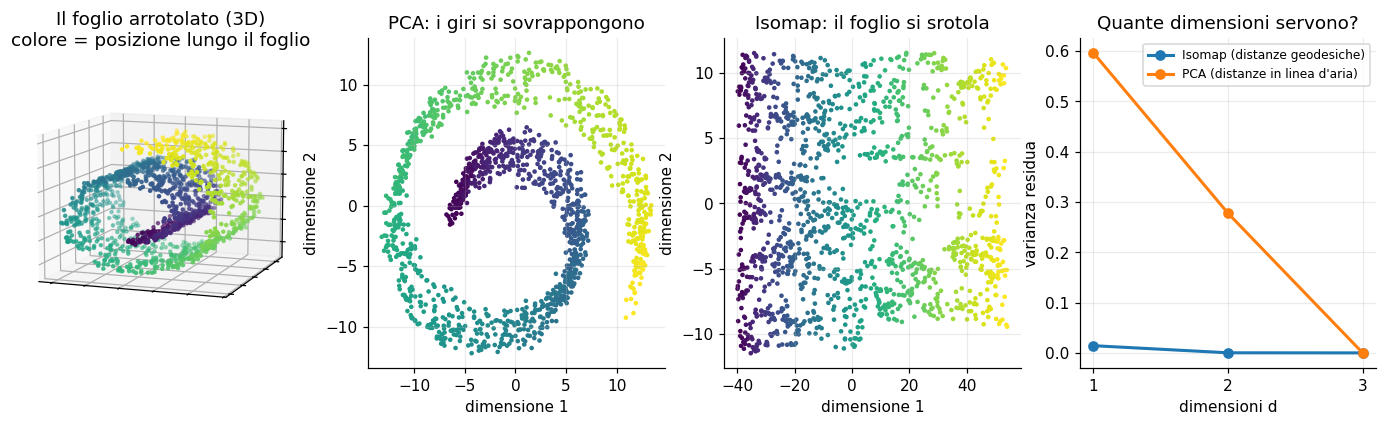

In [6]:
def residual_variance(d_target, Y):                         # 1 - r² tra le distanze da conservare e quelle nella mappa Y
    return 1 - np.corrcoef(d_target, pdist(Y))[0, 1] ** 2   # d_target: lista delle distanze di tutte le coppie (formato di pdist)

def upper(M):                                               # da matrice n × n a lista delle coppie (i < j), nello stesso ordine di pdist
    return M[np.triu_indices(len(M), k=1)]

X_roll, pos_roll = make_swiss_roll(n_samples=1500, noise=0.3, random_state=0)  # 1500 punti sul rotolo; pos_roll = posizione lungo il foglio
roll_pca = PCA(3).fit(X_roll)                               # PCA sui dati 3D
iso_roll = Isomap(n_neighbors=K_NN, n_components=3).fit(X_roll)  # Isomap con lo stesso k dei dati veri
Y_roll_pca, Y_roll_iso = roll_pca.transform(X_roll), iso_roll.embedding_  # coordinate nelle due mappe

rv_roll = pd.DataFrame({                                    # varianza residua per d = 1, 2, 3
    "Isomap (distanze geodesiche)": [residual_variance(upper(iso_roll.dist_matrix_), Y_roll_iso[:, :d]) for d in (1, 2, 3)],
    "PCA (distanze in linea d'aria)": [residual_variance(pdist(X_roll), Y_roll_pca[:, :d]) for d in (1, 2, 3)],
}, index=pd.Index([1, 2, 3], name="dimensioni d"))
display(rv_roll.round(3).T)

fig = plt.figure(figsize=(16, 3.9))
ax0 = fig.add_subplot(1, 4, 1, projection="3d")            # il rotolo nello spazio 3D
ax0.scatter(*X_roll.T, c=pos_roll, cmap="viridis", s=4)
ax0.set(title="Il foglio arrotolato (3D)\ncolore = posizione lungo il foglio"); ax0.view_init(10, -70)
ax0.set_xticklabels([]); ax0.set_yticklabels([]); ax0.set_zticklabels([])
for k, (Y_, ttl) in enumerate([(Y_roll_pca, "PCA: i giri si sovrappongono"),
                               (Y_roll_iso, "Isomap: il foglio si srotola")], start=2):
    a_ = fig.add_subplot(1, 4, k)
    a_.scatter(Y_[:, 0], Y_[:, 1], c=pos_roll, cmap="viridis", s=4)   # stesso colore: se i colori restano in ordine, il foglio è srotolato
    a_.set(title=ttl, xlabel="dimensione 1", ylabel="dimensione 2")
a_ = fig.add_subplot(1, 4, 4)
for col, c in zip(rv_roll.columns, ("C0", "C1")):
    a_.plot(rv_roll.index, rv_roll[col], "o-", color=c, lw=2, label=col)
a_.set(xlabel="dimensioni d", ylabel="varianza residua", xticks=[1, 2, 3], title="Quante dimensioni servono?")
a_.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "03_swiss_roll.png", bbox_inches="tight"); plt.show()

**Lettura.** Nel rotolo, la PCA schiaccia i giri uno sull'altro: colori lontani (punti lontani
lungo il foglio) finiscono sovrapposti. Isomap srotola il foglio e i colori restano in ordine.
La varianza residua dice la stessa cosa in numeri: Isomap è quasi a zero già con 1 dimensione (il
foglio è molto più lungo che largo, quindi la lunghezza pesa quasi tutto) e a zero con **2**, la
dimensione intrinseca del foglio. La PCA ne vuole **3**, la dimensione di embedding. È questa la firma di un manifold curvo che cercheremo nei dati veri: **Isomap scende
più in fretta della PCA**.

Ora rifacciamo i tre passi a mano sui dati veri.

### 3.1 · Passo 1: il grafo dei vicini

In [7]:
G = kneighbors_graph(X, n_neighbors=K_NN, mode="distance")  # matrice sparsa n × n: G[i, j] = distanza se j è tra i 10 vicini di i, altrimenti vuota
n_pieces, _ = connected_components(G, directed=False)       # in quanti pezzi separati è divisa la rete
print(f"{X.shape[0]} punti, {G.nnz} collegamenti (= {X.shape[0]} × {K_NN}), pezzi separati: {n_pieces}")

1106 punti, 11060 collegamenti (= 1106 × 10), pezzi separati: 1


La rete è **un unico pezzo**: da ogni punto si può raggiungere ogni altro camminando lungo le
strade. Se fosse spezzata, tra due pezzi non esisterebbe una distanza geodesica.

### 3.2 · Passo 2: le distanze geodesiche

Per ogni coppia di punti cerchiamo il percorso più breve lungo le strade (algoritmo di Dijkstra,
`method="D"`). `directed=False` vuol dire che ogni strada vale nei due sensi: se j è tra i vicini
di i, si può andare da i a j e da j a i, anche se i non è tra i vicini di j.

In [8]:
D_geo = shortest_path(G, method="D", directed=False)        # n × n: lunghezza del percorso più breve lungo il grafo
D_euc = squareform(pdist(X))                                # n × n: distanza in linea d'aria, per confronto
ratio = upper(D_geo) / upper(D_euc)                         # per ogni coppia: quanto è più lunga la strada a piedi
print(f"Distanza geodesica / distanza in linea d'aria: mediana {np.median(ratio):.2f} "
      f"(10% delle coppie sotto {np.percentile(ratio, 10):.2f}, 10% sopra {np.percentile(ratio, 90):.2f})")
print(f"Correlazione tra le due distanze: dati veri {np.corrcoef(upper(D_geo), upper(D_euc))[0, 1]:.2f}, "
      f"foglio arrotolato {np.corrcoef(upper(iso_roll.dist_matrix_), pdist(X_roll))[0, 1]:.2f}")

Distanza geodesica / distanza in linea d'aria: mediana 1.93 (10% delle coppie sotto 1.53, 10% sopra 2.31)
Correlazione tra le due distanze: dati veri 0.85, foglio arrotolato 0.27


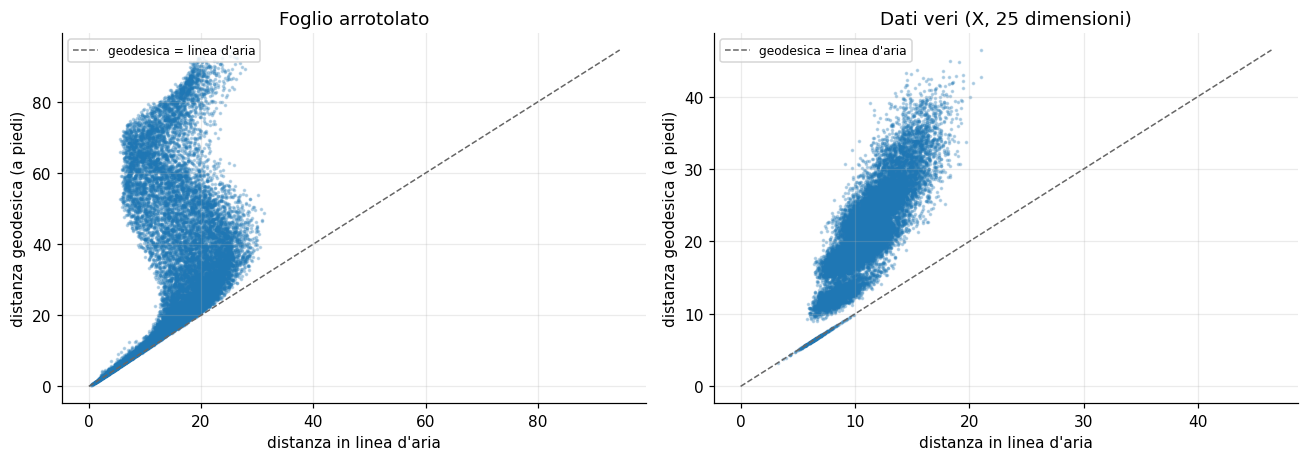

In [9]:
rng = np.random.default_rng(0)                              # seme fisso: stesse coppie a ogni esecuzione
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for a_, (dg, de, ttl) in zip(ax, [(upper(iso_roll.dist_matrix_), pdist(X_roll), "Foglio arrotolato"),
                                  (upper(D_geo), upper(D_euc), "Dati veri (X, 25 dimensioni)")]):
    pick = rng.choice(len(dg), 20000, replace=False)        # 20000 coppie a caso, per non disegnare milioni di punti
    a_.scatter(de[pick], dg[pick], s=2, alpha=0.25, color="C0")
    lim = max(de[pick].max(), dg[pick].max())
    a_.plot([0, lim], [0, lim], "--", color="0.4", lw=1, label="geodesica = linea d'aria")
    a_.set(xlabel="distanza in linea d'aria", ylabel="distanza geodesica (a piedi)", title=ttl)
    a_.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "03_geodesic_vs_euclidean.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Nel foglio arrotolato** la figura si apre a ventaglio: tante coppie sono vicine in linea d'aria
  (a sinistra) ma lontanissime a piedi (in alto). Sono i punti su giri adiacenti del rotolo: è
  l'informazione che la PCA non vede.
- **Nei dati veri** la strada a piedi è in media circa **il doppio** della linea d'aria, ma le due
  distanze vanno quasi di pari passo (correlazione alta). Un rapporto costante dice poco sulla
  curvatura: se la nuvola è rumorosa, anche su una superficie piatta il percorso lungo il grafo fa
  zig-zag tra i punti e risulta più lungo della linea retta. Non c'è il "ventaglio" del rotolo.

Da questa figura non si può ancora concludere nulla: servono le misure del §5.

### 3.3 · Passo 3: MDS classico

Abbiamo le distanze geodesiche; ora cerchiamo coordinate che le riproducano. Il trucco è passare
dalle **distanze** ai **prodotti scalari**, cioè a una matrice che dice quanto due punti "puntano
nella stessa direzione" rispetto al centro della nuvola. Per punti con coordinate vere Y (centrate),
i prodotti scalari sono B = Y Yᵀ, e si ricavano dalle distanze con la **doppia centratura**:

B = −½ · H · D² · H,   con H = I − 1/n (sottrae la media di righe e colonne).

Poi, come nella PCA: autovettori e autovalori di B, e **coordinate = autovettore × √autovalore**.
Il primo asse è quello lungo cui le distanze geodesiche sono più grandi, e così via.

In [10]:
n = X.shape[0]                                              # numero di punti
H = np.eye(n) - 1.0 / n                                     # matrice di centratura: identità meno 1/n in ogni elemento
B = -0.5 * H @ (D_geo ** 2) @ H                             # doppia centratura: dalle distanze geodesiche ai prodotti scalari (n × n)
eigval, eigvec = np.linalg.eigh(B)                          # autovalori e autovettori (B è simmetrica), in ordine crescente
order = np.argsort(eigval)[::-1]                            # indici per l'ordine decrescente
eigval, eigvec = eigval[order], eigvec[:, order]            # prima l'asse con le distanze più grandi
D_MAX = 15                                                  # quante coordinate teniamo
Y_iso = eigvec[:, :D_MAX] * np.sqrt(eigval[:D_MAX])         # coordinate Isomap: autovettore × radice dell'autovalore
print(f"Coordinate Isomap: {Y_iso.shape}")
print(f"Primi 5 autovalori: {np.round(eigval[:5], 0)}")

def negative_share(Dg):                                     # quanto "pesano" gli autovalori negativi rispetto ai positivi
    n_ = len(Dg)
    ev_ = np.linalg.eigvalsh(-0.5 * (np.eye(n_) - 1.0 / n_) @ (Dg ** 2) @ (np.eye(n_) - 1.0 / n_))
    return -ev_[ev_ < 0].sum() / ev_[ev_ > 0].sum()

print(f"Autovalori negativi: {(eigval < 0).sum()} su {n}; peso rispetto ai positivi: "
      f"dati veri {negative_share(D_geo) * 100:.0f}%, foglio arrotolato {negative_share(iso_roll.dist_matrix_) * 100:.0f}%")

Coordinate Isomap: (1106, 15)
Primi 5 autovalori: [50870. 41996. 22678. 20721. 18652.]


Autovalori negativi: 560 su 1106; peso rispetto ai positivi: dati veri 63%, foglio arrotolato 4%


**Gli autovalori negativi.** Se le distanze geodesiche fossero esattamente le distanze tra punti di
uno spazio piatto, B non avrebbe autovalori negativi. Gli autovalori negativi misurano quanto le
distanze geodesiche **non si possono disegnare in nessuno spazio piatto**, qualunque sia il numero
di dimensioni. Nel foglio arrotolato pesano poco: una volta srotolato, il foglio è piatto. Nei dati
veri pesano molto: le distanze lungo il grafo sono deformate dal rumore (lo zig-zag del §3.2), e
nessuna mappa le riproduce bene. È un primo segnale che su questi dati Isomap lavora in condizioni
difficili, come avverte la review: *"degrades when the manifold is (...) strongly corrupted by
noise"*.

### 3.4 · Controllo: coincide con scikit-learn

In [11]:
iso = Isomap(n_neighbors=K_NN, n_components=D_MAX).fit(X)  # la stessa cosa, con scikit-learn
print("Stesse distanze geodesiche:", np.allclose(iso.dist_matrix_, D_geo))
print("Correlazione (in valore assoluto) tra le nostre coordinate e quelle di sklearn, per asse:",
      np.round([abs(np.corrcoef(Y_iso[:, k], iso.embedding_[:, k])[0, 1]) for k in range(D_MAX)], 6))

Stesse distanze geodesiche: True
Correlazione (in valore assoluto) tra le nostre coordinate e quelle di sklearn, per asse: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Coincidono. Come per la PCA (02_new, §6), il **segno** di ogni asse è arbitrario: un asse può
uscire capovolto da un calcolo all'altro. Da qui usiamo `iso`, che ha anche il metodo `transform`
per proiettare punti nuovi (serve ai §6 e §6.1).

### 3.5 · Il ponte con la PCA

Se ogni punto è collegato a **tutti** gli altri (k = n − 1), la strada più breve tra due punti è
quella diretta: le distanze geodesiche diventano quelle in linea d'aria, e Isomap deve dare
esattamente la PCA.

In [12]:
iso_full = Isomap(n_neighbors=n - 1, n_components=3).fit(X)  # grafo completo: ogni punto collegato a tutti
Y_pca3 = PCA(3).fit_transform(X)                            # PCA sugli stessi punti
print("Distanze geodesiche = distanze in linea d'aria:", np.allclose(iso_full.dist_matrix_, D_euc))
print("Correlazione (in valore assoluto) Isomap con k = n − 1 vs PCA, per asse:",
      np.round([abs(np.corrcoef(iso_full.embedding_[:, k], Y_pca3[:, k])[0, 1]) for k in range(3)], 6))

Distanze geodesiche = distanze in linea d'aria: True
Correlazione (in valore assoluto) Isomap con k = n − 1 vs PCA, per asse: [1. 1. 1.]


Identiche. **Isomap contiene la PCA come caso particolare**: con k piccolo misura le distanze
lungo il manifold, con k = n − 1 torna alla PCA. Il numero di vicini k decide quanto "localmente"
guardiamo il manifold (lo variamo al §7.1).

## 4 · Che cosa si vede: Isomap e PCA sugli stessi punti

In alto, ogni punto di X nelle prime due coordinate di Isomap e della PCA, colorato con la fase;
i due pannelli hanno **gli stessi assi**, così si vede anche la differenza di scala tra le mappe.
In basso, le **traiettorie medie** di ogni fase: proiettiamo tutti i bin (a 20 ms) delle finestre
da 1 s del notebook 02 e facciamo la media delle ripetizioni. Per Isomap usiamo `transform`, che
colloca ogni punto nuovo a partire dai suoi vicini tra i punti di X.

La PCA di confronto è stimata **sugli stessi punti X**: stessi dati, cambia solo il modo di
misurare le distanze.

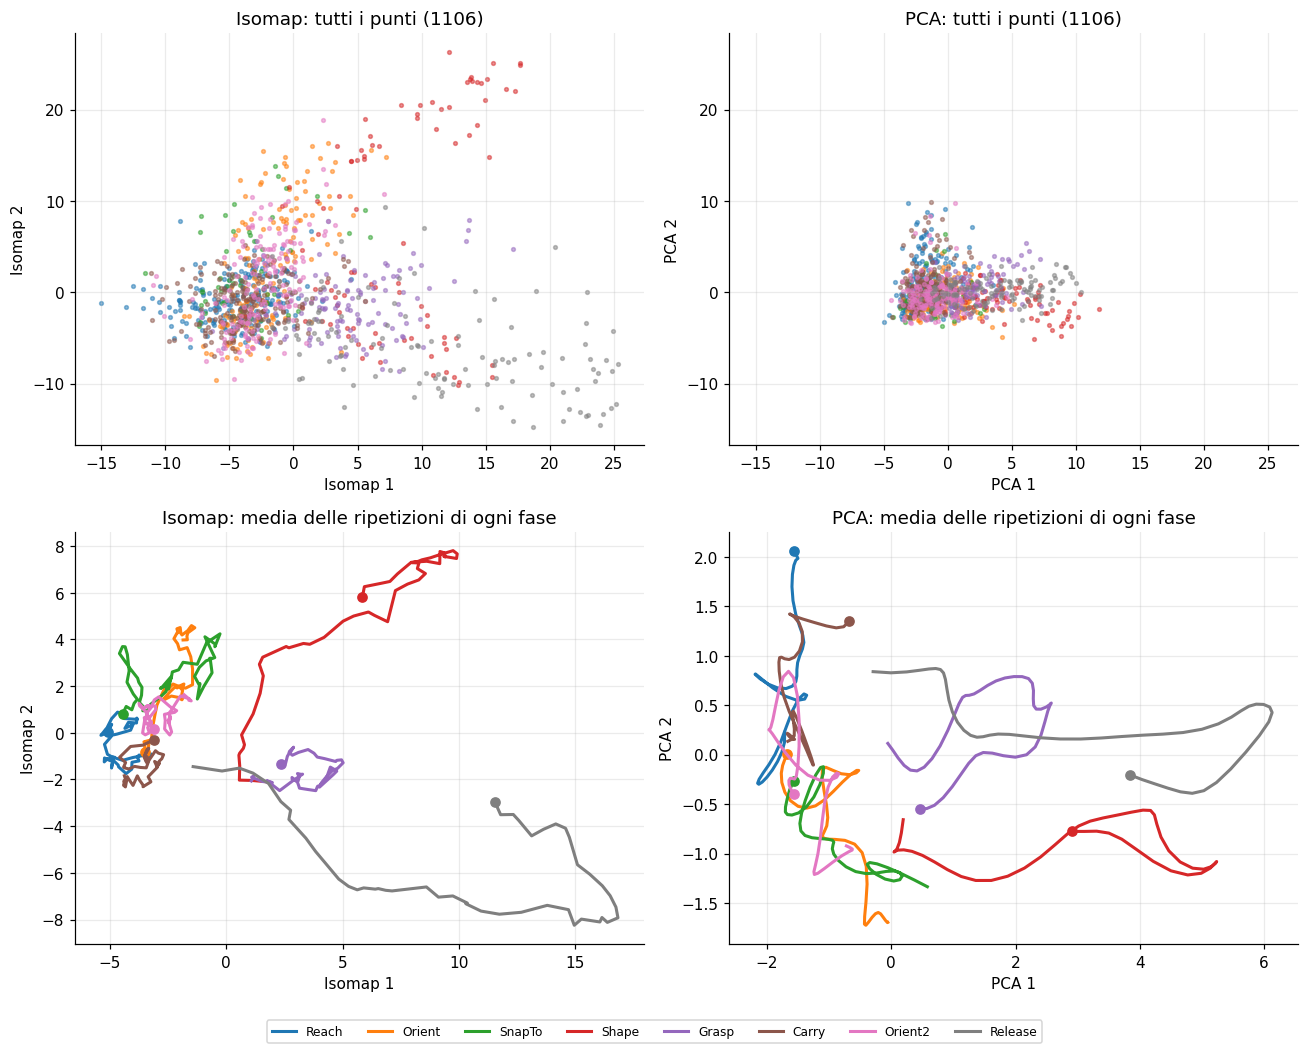

In [13]:
pca_x = PCA(n_components=D_MAX).fit(X)                      # PCA sugli stessi punti di Isomap
Y_pca = pca_x.transform(X)
windows = io.phase_windows(s, win_s=1.0, align="start")     # le 119 finestre da 1 s dall'inizio di ogni fase (notebook 02)
win_X = [Z25[w["start"]:w["stop"]] for w in windows]        # ogni finestra nello spazio a 25 dimensioni (50 bin × 25)
traj = {"Isomap": [iso.transform(x_) for x_ in win_X],      # ogni finestra nelle coordinate Isomap...
        "PCA": [pca_x.transform(x_) for x_ in win_X]}       # ...e in quelle della PCA

fig, ax = plt.subplots(2, 2, figsize=(12, 9.5))
ax[0, 1].sharex(ax[0, 0]); ax[0, 1].sharey(ax[0, 0])        # riga in alto: stessi assi per Isomap e PCA, così si vede la differenza di scala
for j, (name, Y_) in enumerate([("Isomap", iso.embedding_), ("PCA", Y_pca)]):
    for p in io.MOVEMENT_PHASES:                            # nuvola dei punti, un colore per fase
        m = ph == p
        ax[0, j].scatter(Y_[m, 0], Y_[m, 1], s=6, alpha=0.5, color=io.PHASE_COLORS[p])
    ax[0, j].set(title=f"{name}: tutti i punti ({len(X)})", xlabel=f"{name} 1", ylabel=f"{name} 2")
    for p in io.MOVEMENT_PHASES:                            # traiettoria media di ogni fase
        avg = np.mean([t_[:, :2] for t_, w in zip(traj[name], windows) if w["tag"] == p], axis=0)
        ax[1, j].plot(avg[:, 0], avg[:, 1], color=io.PHASE_COLORS[p], lw=2)
        ax[1, j].plot(avg[0, 0], avg[0, 1], "o", color=io.PHASE_COLORS[p], ms=6)  # pallino = inizio della fase
    ax[1, j].set(title=f"{name}: media delle ripetizioni di ogni fase", xlabel=f"{name} 1", ylabel=f"{name} 2")
handles = [plt.Line2D([], [], color=io.PHASE_COLORS[p], lw=2, label=p) for p in io.MOVEMENT_PHASES]
fig.legend(handles=handles, ncol=8, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIGS / "03_isomap_vs_pca.png", bbox_inches="tight"); plt.show()

**Lettura.**

- In entrambe le mappe c'è un grande gruppo centrale in cui si sovrappongono `Reach`, `Orient`,
  `SnapTo`, `Carry` e `Orient2`, e poche fasi che se ne staccano: `Shape` (rosso), `Release`
  (grigio) e in parte `Grasp` (viola). Sono le fasi della mano, le stesse che nel notebook 02
  erano le più riproducibili, coerentemente con la posizione degli array nell'area della mano.
- **Isomap dà più spazio alle fasi della mano**: `Shape` e `Release` si allontanano di più dal
  gruppo centrale, e le loro traiettorie medie sono lunghe e ben separate. La PCA le separa lungo
  la prima componente, ma le schiaccia di più sulle altre. Attenzione però alla scala: nei due
  pannelli in alto, che hanno gli stessi assi, la nuvola di Isomap si estende per più del doppio
  di quella della PCA. Le coordinate di Isomap riproducono distanze misurate **lungo il grafo**,
  che sono sempre maggiori o uguali a quelle in linea d'aria (mediana del rapporto 1.93, §3.2).
  Una parte di questo "più spazio" è quindi attesa per costruzione: quanto ne resta lo dicono le
  misure dei §5 e §6. I pannelli in basso hanno invece assi liberi, per leggere la forma delle
  traiettorie.
- Le traiettorie medie di Isomap sono **seghettate**, quelle della PCA lisce. `transform` colloca
  ogni punto nuovo a partire dai suoi vicini tra i punti di X, e quando i vicini cambiano il punto
  salta (lo misuriamo al §6.1).

Le figure dicono dove guardare, non quanto è grande la differenza: per quello servono le misure
dei §5 e §6.

## 5 · Il manifold è curvo?

### 5.1 · La varianza residua sui dati veri

È la misura del foglio arrotolato (§3): per ogni numero di dimensioni d, quanto delle distanze da
conservare la mappa **non** riproduce. Se il manifold è curvo, la curva di Isomap scende più in
fretta di quella della PCA e ha un gomito alla dimensione intrinseca.

In [14]:
D_LIST = np.arange(1, D_MAX + 1)                            # d = 1, ..., 15

def rv_curves(Xp, k=K_NN, forbid=None):                     # varianza residua di Isomap e della PCA per d = 1..15
    iso_ = isomap_on(Xp, k, D_MAX, forbid)
    Yp_ = PCA(D_MAX, svd_solver="full").fit_transform(Xp)   # svd_solver="full": calcolo esatto, senza la parte casuale del risolutore rapido
    r_iso = [residual_variance(upper(iso_.dist_matrix_), iso_.embedding_[:, :d]) for d in D_LIST]
    r_pca = [residual_variance(pdist(Xp), Yp_[:, :d]) for d in D_LIST]
    return np.array(r_iso), np.array(r_pca)

def isomap_on(Xp, k, d, forbid=None):                       # Isomap che accetta anche coppie vietate (finestra di Theiler, §7.2)
    D = squareform(pdist(Xp))                               # distanze in linea d'aria
    if forbid is not None:
        D[forbid] = 1e3 * D.max()                           # una coppia vietata ha distanza enorme: non sarà mai scelta come vicina
    return Isomap(n_neighbors=k, n_components=d, metric="precomputed").fit(D)

rv_iso, rv_pca = rv_curves(X)
display(pd.DataFrame({"Isomap": rv_iso, "PCA": rv_pca, "vantaggio di Isomap (PCA − Isomap)": rv_pca - rv_iso},
                     index=pd.Index(D_LIST, name="d")).round(3).T)

d,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Isomap,0.580,0.438,0.377,0.338,0.303,0.274,0.247,0.234,0.216,0.198,0.188,0.180,0.172,0.165,0.160
PCA,0.614,0.473,0.413,0.358,0.320,0.287,0.250,0.227,0.201,0.184,0.163,0.148,0.133,0.120,0.105
vantaggio di Isomap (PCA − Isomap),0.034,0.036,0.036,0.020,0.017,0.013,0.003,-0.006,-0.014,-0.014,-0.025,-0.032,-0.039,-0.045,-0.054


**Lettura.**

- **Isomap è un po' meglio della PCA con poche dimensioni**: circa 3.5 punti percentuali in meno
  di varianza residua con d = 1, 2, 3. Il vantaggio si riduce e sparisce intorno a d = 7; con
  molte dimensioni vince la PCA. Questo è atteso: con abbastanza dimensioni la PCA riproduce per
  costruzione le distanze in linea d'aria, mentre le distanze geodesiche non si possono riprodurre
  del tutto in nessuno spazio piatto (gli autovalori negativi del §3.3).
- **Nessun gomito.** Le due curve scendono dolcemente. A differenza del foglio arrotolato, non
  c'è un numero di dimensioni oltre il quale "non serve altro".

Il vantaggio di Isomap è piccolo. È un segno di curvatura o un effetto del modo in cui Isomap
tratta il rumore?

### 5.2 · Il controllo decisivo: un "gemello" dei dati senza curvatura

Isomap batte la PCA di poco. Ma quel poco potrebbe venire da come Isomap tratta il rumore e la
catena del tempo, non da una vera curvatura. Per saperlo serve un termine di confronto: un insieme
di dati **gemello** di X, con le stesse proprietà che vede la PCA, ma **piatto per costruzione**.

**Come si costruisce: i surrogati a fasi casuali** (Theiler et al. 1992; Prichard & Theiler 1994).
Ogni segnale nel tempo si può scrivere come somma di oscillazioni di frequenze diverse (Fourier).
Per ogni oscillazione ci sono due numeri:

- l'**ampiezza**, che dice quanto pesa quella frequenza: da qui vengono la varianza, le
  correlazioni tra dimensioni e quanto in fretta il segnale cambia nel tempo;
- la **fase**, che dice in che momento l'oscillazione ha il picco: è l'allineamento preciso delle
  fasi a creare le forme, come curve e gruppi separati.

Teniamo le ampiezze e **mescoliamo le fasi a caso**, con lo stesso mescolamento per tutte le 25
dimensioni. È come un'orchestra con gli stessi strumenti allo stesso volume, ma in cui ognuno
attacca in un momento a caso: il "timbro" resta, la melodia sparisce. Il gemello ha la stessa
covarianza (quindi la stessa PCA) e la stessa velocità di variazione (quindi la stessa catena del
tempo), ma è una nuvola gaussiana **senza curvatura**.

Lo costruiamo su tutta la sessione (il segnale continuo) e poi prendiamo gli stessi bin di X.
Ripetiamo con 5 mescolamenti diversi.

In [15]:
def phase_randomize(Xt, seed):                              # surrogato: stesse ampiezze di Fourier, fasi casuali (uguali per tutte le colonne)
    rng_ = np.random.default_rng(seed)
    F = np.fft.rfft(Xt - Xt.mean(0), axis=0)                # spettro di ogni colonna: un numero complesso per frequenza
    phases = np.exp(2j * np.pi * rng_.uniform(size=F.shape[0]))  # una fase casuale per ogni frequenza
    phases[0] = 1                                           # la componente costante non si tocca
    if len(Xt) % 2 == 0:
        phases[-1] = 1                                      # nemmeno quella alla frequenza massima (deve restare reale)
    return np.fft.irfft(F * phases[:, None], n=len(Xt), axis=0) + Xt.mean(0)  # si torna nel tempo

N_SUR = 5                                                   # quanti surrogati
sur = [phase_randomize(Z25, seed)[bins] for seed in range(N_SUR)]  # i gemelli di X, sugli stessi bin
c_real, c_sur = np.cov(X.T), np.cov(sur[0].T)               # covarianze tra le 25 dimensioni
print(f"Covarianza del gemello vs dati veri: correlazione tra gli elementi {np.corrcoef(c_real.ravel(), c_sur.ravel())[0, 1]:.3f}")
print(f"Catena del tempo (vicini dello stesso trial entro 200 ms): dati veri "
      f"{neighbor_mix(knn_index(X), bins)['catena del tempo'] * 100:.0f}%, gemello "
      f"{neighbor_mix(knn_index(sur[0]), bins)['catena del tempo'] * 100:.0f}%")

rv_sur = [rv_curves(Xs) for Xs in sur]                      # varianza residua di Isomap e PCA su ogni gemello
rv_iso_s = np.array([r[0] for r in rv_sur]); rv_pca_s = np.array([r[1] for r in rv_sur])
adv_real, adv_sur = rv_pca - rv_iso, rv_pca_s - rv_iso_s    # vantaggio di Isomap: sui dati e su ogni gemello
display(pd.DataFrame({"vantaggio di Isomap, dati veri": adv_real,
                      "vantaggio di Isomap, gemelli (media)": adv_sur.mean(0),
                      "gemelli, minimo": adv_sur.min(0), "gemelli, massimo": adv_sur.max(0)},
                     index=pd.Index(D_LIST, name="d")).round(3).T)

Covarianza del gemello vs dati veri: correlazione tra gli elementi 0.965
Catena del tempo (vicini dello stesso trial entro 200 ms): dati veri 20%, gemello 21%


d,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
"vantaggio di Isomap, dati veri",0.034,0.036,0.036,0.020,0.017,0.013,0.003,-0.006,-0.014,-0.014,-0.025,-0.032,-0.039,-0.045,-0.054
"vantaggio di Isomap, gemelli (media)",-0.042,-0.069,-0.096,-0.121,-0.129,-0.143,-0.155,-0.161,-0.169,-0.177,-0.184,-0.193,-0.198,-0.207,-0.214
"gemelli, minimo",-0.088,-0.097,-0.137,-0.174,-0.165,-0.172,-0.173,-0.179,-0.188,-0.189,-0.193,-0.202,-0.211,-0.223,-0.227
"gemelli, massimo",-0.016,-0.047,-0.053,-0.070,-0.093,-0.118,-0.135,-0.143,-0.151,-0.165,-0.167,-0.177,-0.183,-0.192,-0.199


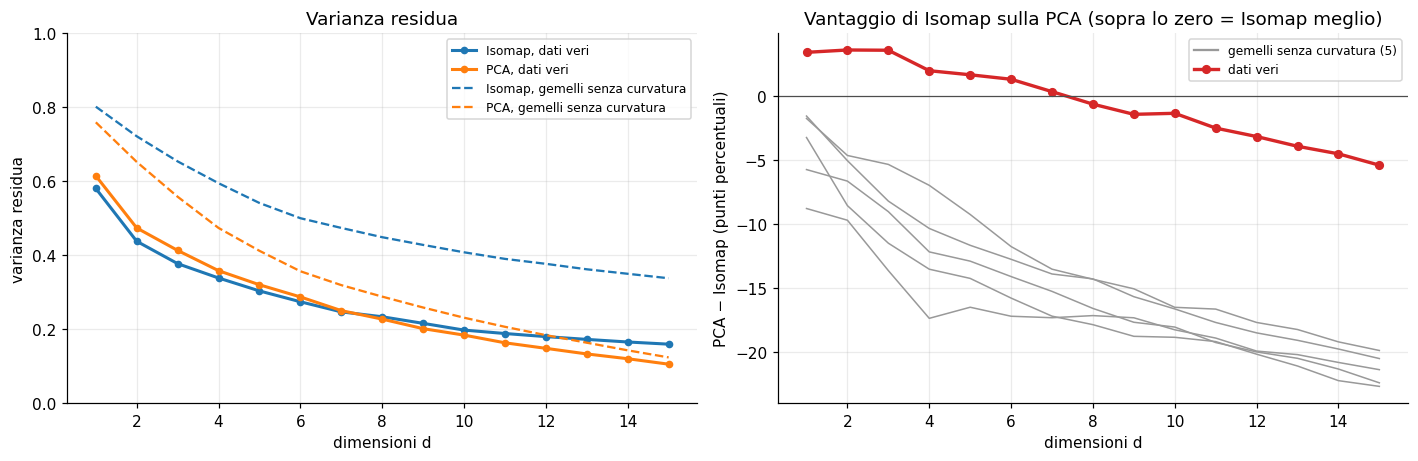

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(D_LIST, rv_iso, "o-", color="C0", lw=2, ms=4, label="Isomap, dati veri")
ax[0].plot(D_LIST, rv_pca, "o-", color="C1", lw=2, ms=4, label="PCA, dati veri")
ax[0].plot(D_LIST, rv_iso_s.mean(0), "--", color="C0", lw=1.5, label="Isomap, gemelli senza curvatura")
ax[0].plot(D_LIST, rv_pca_s.mean(0), "--", color="C1", lw=1.5, label="PCA, gemelli senza curvatura")
ax[0].set(xlabel="dimensioni d", ylabel="varianza residua", ylim=(0, 1), title="Varianza residua")
ax[0].legend(fontsize=8)
for a_s in adv_sur:
    ax[1].plot(D_LIST, a_s * 100, color="0.6", lw=1)        # un gemello per linea
ax[1].plot([], [], color="0.6", label=f"gemelli senza curvatura ({N_SUR})")
ax[1].plot(D_LIST, adv_real * 100, "o-", color="C3", lw=2.2, ms=5, label="dati veri")
ax[1].axhline(0, color="0.3", lw=0.8)
ax[1].set(xlabel="dimensioni d", ylabel="PCA − Isomap (punti percentuali)",
          title="Vantaggio di Isomap sulla PCA (sopra lo zero = Isomap meglio)")
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "03_residual_variance.png", bbox_inches="tight"); plt.show()

**Lettura.**

- Il gemello ha davvero le stesse proprietà "lineari" dei dati: stessa covarianza (correlazione
  0.97 tra gli elementi) e stessa catena del tempo (20% contro 21%).
- **Sul gemello senza curvatura Isomap perde sempre**, e di molto: da −4 punti con d = 1 a −21
  con d = 15, in tutti e 5 i gemelli. È quello che ci si aspetta: su una nuvola piatta e
  rumorosa, le distanze lungo il grafo sono solo distanze in linea d'aria deformate dallo zig-zag.
- **Sui dati veri Isomap vince invece di perdere** (fino a d = 6). Con d = 3: +3.6 punti contro
  −9.6 in media nei gemelli (−5.3 nel migliore). La distanza tra la curva rossa e quelle grigie,
  circa 13 punti con d = 3, è la parte di struttura che una nuvola piatta con le stesse varianze,
  le stesse correlazioni e la stessa velocità nel tempo **non** ha.
- Nel pannello di sinistra entrambi i metodi hanno una varianza residua molto più bassa sui dati
  veri che sui gemelli: le distanze dei dati veri sono dominate da poche escursioni grandi (le fasi
  della mano del §4), più facili da riprodurre con poche dimensioni.

**Conclusione**, con una precisazione onesta. Il controllo esclude che il vantaggio di Isomap
venga dal rumore o dalla catena del tempo: c'è struttura **non lineare**. Il gemello però è anche
**gaussiano**, i dati veri no. Il controllo dice quindi "c'è qualcosa che un modello lineare e
gaussiano non spiega": può essere curvatura, ma anche gruppi separati o valori estremi rari. Per
distinguere servirebbe un gemello che conserva anche la distribuzione dei valori (surrogati IAAFT,
Schreiber & Schmitz 1996); qui non l'abbiamo fatto.

**Risposte alle domande 1 e 2.** Il manifold ha una componente non lineare, ma **modesta**. Isomap
**non** trova una dimensione intrinseca piccola e netta nei dati single-trial: la curva non ha
gomito.

### 5.3 · Un secondo modo di stimare la dimensione intrinseca: TwoNN

La varianza residua guarda **tutte** le distanze, anche tra punti lontani. Esistono stimatori
**locali**, che guardano solo i vicinissimi. Il più usato è **TwoNN** (Facco et al. 2017): per ogni
punto si prende il rapporto μ = r₂ / r₁ tra la distanza dal secondo e dal primo vicino. In un
manifold a d dimensioni, μ segue una legge nota che dipende solo da d: basta una retta per stimare d.
L'abbiamo annunciato come stimatore "indipendente dal metodo"; vediamo se regge.

Lo applichiamo a tutti i bin di movimento (uno ogni 20 ms) e a un bin ogni 5, anche con la
**finestra di Theiler** (Theiler 1986): si vieta di scegliere come vicini i punti dello stesso trial
a meno di 100 o 200 ms, per togliere la catena del tempo. E lo confrontiamo con il gemello.

In [17]:
def twonn(Xp, forbid=None, discard=0.1):                    # stima TwoNN della dimensione intrinseca (Facco et al. 2017)
    D = squareform(pdist(Xp)); np.fill_diagonal(D, np.inf)  # distanze, senza il punto stesso
    if forbid is not None:
        D[forbid] = np.inf                                  # coppie vietate
    r = np.partition(D, 1, axis=1)[:, :2]                   # distanza dal primo e dal secondo vicino
    mu = np.sort(r[:, 1] / r[:, 0])                         # rapporto μ = r2 / r1, in ordine crescente
    n_ = len(mu); mu = mu[: int(n_ * (1 - discard))]        # scarta il 10% dei rapporti più grandi (i più rumorosi)
    F = np.arange(1, len(mu) + 1) / n_                      # frazione di punti con rapporto ≤ μ
    x_, y_ = np.log(mu), -np.log(1 - F)                     # in queste coordinate la legge è una retta per l'origine...
    return (x_ @ y_) / (x_ @ x_)                            # ...la cui pendenza è d

def theiler_mask(b, win_bins):                              # coppie dello stesso trial più vicine di win_bins (esclusa la diagonale)
    m = (trial[b][:, None] == trial[b][None, :]) & (np.abs(b[:, None] - b[None, :]) <= win_bins)
    np.fill_diagonal(m, False)
    return m

Z25_sur = phase_randomize(Z25, 0)                           # un gemello di tutta la sessione
rows = []
for step in (1, 5):                                         # tutti i bin, oppure uno ogni 5
    b_ = bins_all[bins_all % step == 0]
    for w_ms in (0, 100, 200):                              # finestra di Theiler: nessuna, ±100 ms, ±200 ms
        fb = theiler_mask(b_, w_ms // 20) if w_ms else None
        rows.append({"un bin ogni": step, "finestra di Theiler (ms)": w_ms,
                     "TwoNN, dati veri": twonn(Z25[b_], fb), "TwoNN, gemello": twonn(Z25_sur[b_], fb)})
display(pd.DataFrame(rows).set_index(["un bin ogni", "finestra di Theiler (ms)"]).round(1))

TwoNN, dati veri  TwoNN, gemello
un bin ogni finestra di Theiler (ms)                                  
1           0                                     11.3            12.2
            100                                   22.6            24.0
            200                                   67.7            72.7
5           0                                      7.5             7.9
            100                                   16.6            18.4
            200                                   17.7            18.8

**Lettura.**

- Le stime vanno **da 7.5 a 68** a seconda di quanti punti teniamo e di quanto è larga la
  finestra di Theiler: non c'è un valore stabile.
- Soprattutto, **il gemello senza curvatura dà quasi gli stessi numeri** dei dati veri (al
  massimo 5 di differenza su 70, di solito 1-2). TwoNN guarda solo i vicinissimi, e a quella scala i dati sono dominati dal rumore e dalla
  struttura nel tempo, che il gemello conserva. Qualunque numero dia, non sta misurando il
  manifold.

Non usiamo TwoNN come stima della dimensione intrinseca: su questi dati il confronto globale del
§5.2, che ha un termine di confronto, è più affidabile. TwoNN resta tra le alternative provate.

## 6 · Le fasi si riconoscono meglio nelle coordinate di Isomap?

Una misura più concreta: dalle coordinate di un istante, riusciamo a dire **in che fase del task**
si trova il partecipante? Se Isomap "srotola" il manifold, fasi diverse dovrebbero finire in zone
diverse della mappa.

- **Classificatore a vicini** (k = 10): per un punto nuovo si guardano i 10 punti di training più
  vicini nella mappa e vince la fase più votata. È il classificatore più semplice che non assume
  confini lineari, quindi non svantaggia Isomap.
- **Accuratezza bilanciata**: la media, sulle 8 fasi, della frazione di punti riconosciuti. Pesa
  allo stesso modo fasi lunghe e corte. **A caso: 1/8 = 12.5%**.
- **Cross-validation per trial** (5 blocchi da 3 trial): PCA, Isomap e classificatore si stimano
  sui trial di training; i punti dei trial di test si proiettano con `transform`. Nessun bin dello
  stesso trial finisce sia nel training sia nel test.

Confrontiamo Isomap e PCA con lo stesso numero di dimensioni d.

In [18]:
D_DEC = (2, 3, 5, 10, 25)                                   # dimensioni provate

def decode_clean(source, b, K=K_PCA, fit_bins=bins_all, k=K_NN, d_list=D_DEC, forbid_win=0):
    """Accuratezza bilanciata (%) di Isomap e PCA per ogni d, con cross-validation per trial.
    source: dati di tutta la sessione; b: bin usati come punti; K: dimensioni della PCA iniziale (None = nessuna);
    fit_bins: bin su cui si stima la PCA iniziale; forbid_win: finestra di Theiler in bin (0 = nessuna)."""
    keep = MOV[b]                                           # il classificatore impara e si valuta solo sui bin di movimento
    pred = {(m, d): np.empty(len(b), dtype=object) for m in ("Isomap", "PCA") for d in d_list}
    for trn, tst in GroupKFold(n_splits=5).split(b, groups=trial[b]):  # 5 blocchi da 3 trial: ogni trial nel test una volta sola
        if K is None:                                       # nessuna PCA iniziale
            Xtr, Xte = source[b[trn]], source[b[tst]]
        else:                                               # la PCA iniziale vede solo i trial di training
            train_trials = np.unique(trial[b[trn]])
            pca_f = PCA(K).fit(source[fit_bins[np.isin(trial[fit_bins], train_trials)]])
            Xtr, Xte = pca_f.transform(source[b[trn]]), pca_f.transform(source[b[tst]])
        fb = theiler_mask(b[trn], forbid_win) if forbid_win else None
        iso_f = isomap_on(Xtr, k, max(d_list), fb)          # Isomap sui soli punti di training
        pca_d = PCA(max(d_list), svd_solver="full").fit(Xtr)  # PCA sugli stessi punti (calcolo esatto: con 160 colonne il predefinito ha una parte casuale)
        E = {"Isomap": (iso_f.embedding_, iso_f.transform(cdist(Xte, Xtr))),  # punti di test proiettati con transform
             "PCA": (pca_d.transform(Xtr), pca_d.transform(Xte))}
        for m, (Etr, Ete) in E.items():
            for d in d_list:                                # le prime d coordinate
                clf = KNeighborsClassifier(n_neighbors=10).fit(Etr[keep[trn], :d], phase[b[trn]][keep[trn]])
                pred[(m, d)][tst] = clf.predict(Ete[:, :d])
    return {(m, d): balanced_accuracy_score(phase[b][keep], pred[(m, d)][keep]) * 100 for (m, d) in pred}

acc = decode_clean(Z, bins)                                 # configurazione principale
tab_dec = pd.DataFrame({m: [acc[(m, d)] for d in D_DEC] for m in ("Isomap", "PCA")},
                       index=pd.Index(D_DEC, name="dimensioni d"))
display(tab_dec.round(1).T)

dimensioni d,2,3,5,10,25
Isomap,31.8,36.0,37.7,38.9,37.0
PCA,26.0,32.4,35.0,41.7,42.2


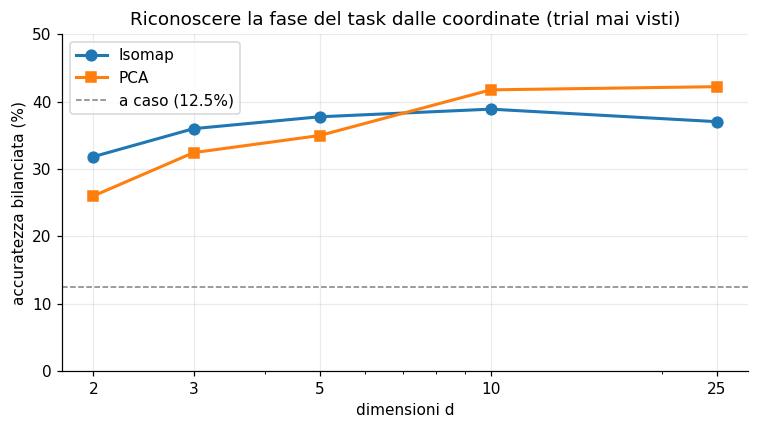

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(D_DEC, tab_dec["Isomap"], "o-", color="C0", lw=2, ms=7, label="Isomap")
ax.plot(D_DEC, tab_dec["PCA"], "s-", color="C1", lw=2, ms=7, label="PCA")
ax.axhline(100 / 8, color="0.5", ls="--", lw=1, label="a caso (12.5%)")
ax.set(xscale="log", xticks=D_DEC, xticklabels=D_DEC, xlabel="dimensioni d", ylabel="accuratezza bilanciata (%)",
       ylim=(0, 50), title="Riconoscere la fase del task dalle coordinate (trial mai visti)")
ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "03_phase_decoding.png", bbox_inches="tight"); plt.show()

**Lettura.**

- Tutti i valori sono **ben sopra il caso** (12.5%): anche 2 dimensioni contengono informazione
  sulla fase.
- **Con poche dimensioni (2-5) Isomap è meglio della PCA**: +6 punti con d = 2, +3.6 con d = 3. È
  coerente con la varianza residua: Isomap mette più struttura nelle prime coordinate.
- **Con 10-25 dimensioni vince la PCA** (circa 42% contro 37-39%), ed è anche il valore più alto
  in assoluto. Isomap quindi non trova informazione in più: **comprime** quella che c'è in meno
  dimensioni. È utile per guardare i dati in 2-3 dimensioni, non per riconoscere meglio le fasi.
- I valori assoluti restano bassi (circa 40%) perché le fasi del braccio (`Reach`, `Orient`,
  `Carry`, `Orient2`) si confondono tra loro, come si vedeva al §4 e come diceva la consistenza
  quasi nulla di queste fasi nel notebook 02.

### 6.1 · Le traiettorie single-trial

Ultima misura, la stessa del notebook 02: prendiamo le 119 finestre da 1 s (tutti i bin, uno ogni
20 ms), le proiettiamo con Isomap e con la PCA, e calcoliamo sulle prime 3 dimensioni la
**seghettatura** (quanto la traiettoria salta da un bin all'altro) e la **consistenza** (quanto si
somigliano le ripetizioni della stessa fase). Le funzioni sono quelle del 02_new (§9.4).

,seghettatura (più bassa = meglio),consistenza (più alta = meglio)
metodo,,
PCA,0.0126,0.0879
Isomap,0.2747,0.0951


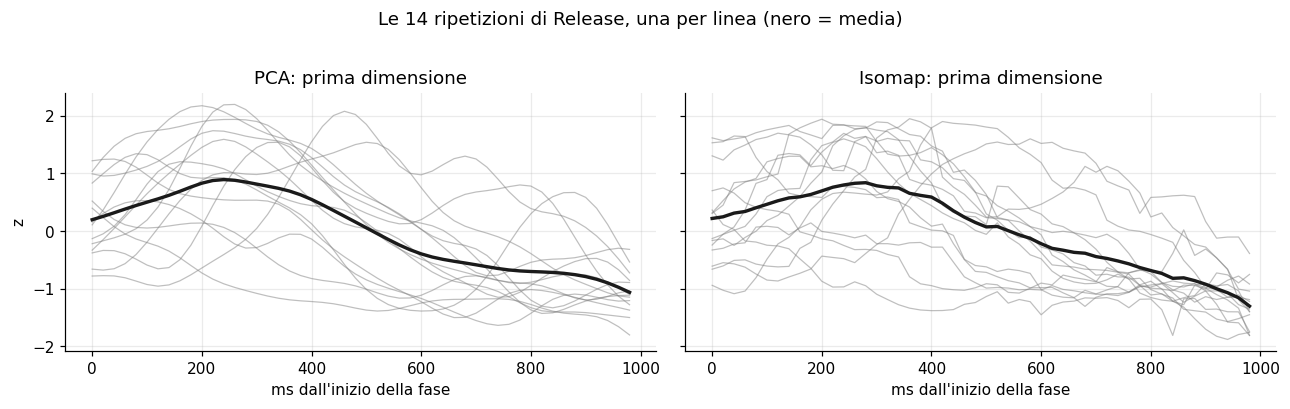

In [20]:
def roughness(trajs):                                       # seghettatura media (02_new, §9.4)
    return float(np.mean([(np.diff((T_ - T_.mean(0)) / (T_.std(0) + 1e-9), n=2, axis=0) ** 2).mean()
                          for T_ in trajs]))                # z-score di ogni dimensione, poi differenza seconda al quadrato

def consistency(trajs):                                     # correlazione media tra ripetizioni della stessa fase (02_new, §9.4)
    tags_ = [w["tag"] for w in windows]
    out = []
    for p in io.MOVEMENT_PHASES:
        R = np.stack([t_ for t_, tg in zip(trajs, tags_) if tg == p])  # (ripetizioni, 50 bin, 3 dimensioni)
        out.append(np.mean([np.corrcoef(R[:, :, j])[np.triu_indices(len(R), 1)].mean() for j in range(R.shape[2])]))
    return float(np.mean(out))

tab_traj = pd.DataFrame([{"metodo": m, "seghettatura (più bassa = meglio)": roughness([t_[:, :3] for t_ in traj[m]]),
                          "consistenza (più alta = meglio)": consistency([t_[:, :3] for t_ in traj[m]])}
                         for m in ("PCA", "Isomap")]).set_index("metodo")
display(tab_traj.round(4))

PH_SHOW = "Release"                                         # la fase più riproducibile nel notebook 02
idx_ph = [i for i, w in enumerate(windows) if w["tag"] == PH_SHOW]
t_win = np.arange(50) * 20                                  # ms dall'inizio della fase
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a_, m in zip(ax, ("PCA", "Isomap")):
    R = np.stack([traj[m][i][:, 0] for i in idx_ph])        # prima dimensione di ogni ripetizione
    R = (R - R.mean()) / R.std()                            # stessa scala per i due metodi
    for r_ in R:
        a_.plot(t_win, r_, color=io.PHASE_COLORS[PH_SHOW], lw=0.8, alpha=0.5)
    a_.plot(t_win, R.mean(0), color="0.1", lw=2.2)          # media delle ripetizioni
    a_.set(title=f"{m}: prima dimensione", xlabel="ms dall'inizio della fase")
ax[0].set_ylabel("z")
fig.suptitle(f"Le {len(idx_ph)} ripetizioni di {PH_SHOW}, una per linea (nero = media)", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "03_trajectories.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Consistenza simile**, appena più alta per Isomap: le ripetizioni della stessa fase si
  somigliano un po' di più.
- **Seghettatura circa 20 volte più alta.** È un limite strutturale di Isomap: non produce una
  funzione liscia che porta dai dati alle coordinate. `transform` colloca ogni punto nuovo
  guardando i suoi 10 vicini tra i punti di X; quando il gruppo dei vicini cambia, il punto salta.
  Nella figura si vede come un tremolio sulle curve di Isomap, assente in quelle della PCA.
- È il terzo limite comune dei metodi geometrici indicato dalla review (§4.1): danno una mappa
  descrittiva, non un modello dei dati. Per le traiettorie single-trial il riferimento resta la
  GPFA del notebook 02 (seghettatura 0.011, consistenza 0.11).

## 7 · Analisi di sensibilità e alternative provate

Cambiamo **una scelta alla volta** rispetto alla configurazione principale e, per ogni variante,
calcoliamo le stesse misure:

- la composizione dei vicini (§2);
- il **vantaggio di Isomap sulla PCA** nella varianza residua con d = 3 (§5), sui dati e su un
  gemello senza curvatura (§5.2): conta la **differenza** tra i due;
- il riconoscimento della fase con d = 3, per Isomap e per la PCA, sempre con la stima pulita del
  §6.

**Una scorciatoia scartata.** Per risparmiare tempo si potrebbe stimare Isomap una volta sola su
**tutti** i punti (non vede le etichette, quindi sembra innocuo) e fare la cross-validation solo
sul classificatore. Lo controlliamo sulla configurazione principale.

In [21]:
def decode_shortcut(E, b):                                  # la scorciatoia: coordinate stimate su tutti i punti, CV solo sul classificatore
    keep = MOV[b]
    E_, ph_, tr_ = E[keep], phase[b][keep], trial[b][keep]
    pred = np.empty(len(E_), dtype=object)
    for trn, tst in GroupKFold(n_splits=5).split(E_, groups=tr_):
        pred[tst] = KNeighborsClassifier(n_neighbors=10).fit(E_[trn], ph_[trn]).predict(E_[tst])
    return balanced_accuracy_score(ph_, pred) * 100

print(f"Fase riconosciuta con d = 3, Isomap: stima pulita {tab_dec.loc[3, 'Isomap']:.1f}%, "
      f"scorciatoia {decode_shortcut(iso.embedding_[:, :3], bins):.1f}%")
print(f"                              PCA:    stima pulita {tab_dec.loc[3, 'PCA']:.1f}%, "
      f"scorciatoia {decode_shortcut(Y_pca[:, :3], bins):.1f}%")

Fase riconosciuta con d = 3, Isomap: stima pulita 36.0%, scorciatoia 41.0%
                              PCA:    stima pulita 32.4%, scorciatoia 34.5%


**La scorciatoia è ottimista**: Isomap passa da 36.0% a 41.0% (+5 punti), la PCA da 32.4% a 34.5%
(+2). Il vantaggio di Isomap sembrerebbe quasi il doppio. Il motivo: se Isomap si stima su tutti i
punti, anche quelli dei trial di test contribuiscono a costruire la mappa. Le etichette non
entrano, ma la geometria sì, e la mappa si adatta anche ai punti su cui poi si valuta. **Da qui
usiamo sempre la stima pulita**, anche se è più lenta.

### 7.1 · Il numero di vicini k

In [22]:
D_EVAL = 3                                                  # dimensioni usate nelle misure riassuntive

def evaluate(source, b, K=K_PCA, fit_bins=bins_all, k=K_NN, forbid_win=0, surrogate=True, decode=True):
    """Tutte le misure per un input: source = dati di tutta la sessione, b = bin usati come punti.
    Le PCA usano svd_solver="full" (calcolo esatto): con 160 colonne il valore predefinito sceglierebbe un risolutore
    rapido che ha una parte casuale, e il risultato cambierebbe un po' da un'esecuzione all'altra."""
    Xf = PCA(K, svd_solver="full").fit(source[fit_bins]).transform(source) if K else source  # input di tutta la sessione (per vicini, varianza residua, gemello)
    Xp = Xf[b]
    fb = theiler_mask(b, forbid_win) if forbid_win else None
    mix_ = neighbor_mix(knn_index(Xp, k, fb), b, MOV[b])
    iso_ = isomap_on(Xp, k, D_EVAL, fb)
    adv = residual_variance(pdist(Xp), PCA(D_EVAL, svd_solver="full").fit_transform(Xp)) - \
          residual_variance(upper(iso_.dist_matrix_), iso_.embedding_)
    if surrogate:                                           # stessa misura su un gemello senza curvatura
        Xs = phase_randomize(Xf, 0)[b]
        iso_s = isomap_on(Xs, k, D_EVAL, fb)
        adv_s = residual_variance(pdist(Xs), PCA(D_EVAL, svd_solver="full").fit_transform(Xs)) - \
                residual_variance(upper(iso_s.dist_matrix_), iso_s.embedding_)
    else:
        adv_s = np.nan
    acc_ = (decode_clean(source, b, K=K, fit_bins=fit_bins, k=k, d_list=(D_EVAL,), forbid_win=forbid_win) if decode
            else {("Isomap", D_EVAL): np.nan, ("PCA", D_EVAL): np.nan})
    return {"punti": len(b), "pezzi del grafo": connected_components(kneighbors_graph(Xp, k), directed=False)[0] if fb is None else np.nan,
            "catena del tempo (%)": mix_["catena del tempo"] * 100,
            "stessa fase, altro trial (%)": mix_["stessa fase, altro trial"] * 100,
            "vantaggio Isomap, dati": adv * 100, "vantaggio Isomap, gemello": adv_s * 100,
            "fase riconosciuta, Isomap (%)": acc_[("Isomap", D_EVAL)],
            "fase riconosciuta, PCA (%)": acc_[("PCA", D_EVAL)]}

K_LIST = (5, 10, 15, 20, 30, 50)
tab_k = pd.DataFrame([evaluate(Z, bins, k=k) for k in K_LIST], index=pd.Index(K_LIST, name="vicini k"))
display(tab_k.round(1))

,punti,pezzi del grafo,catena del tempo (%),"stessa fase, altro trial (%)","vantaggio Isomap, dati","vantaggio Isomap, gemello","fase riconosciuta, Isomap (%)","fase riconosciuta, PCA (%)"
vicini k,,,,,,,,
5,1106,1,34.7,23.1,4.7,-10.5,33.1,32.4
10,1106,1,20.4,27.1,3.6,-9.0,36.0,32.4
15,1106,1,14.8,28.2,3.7,-10.4,33.4,32.4
20,1106,1,11.6,28.1,1.2,-11.8,34.6,32.4
30,1106,1,8.3,27.9,-1.3,-8.8,34.2,32.4
50,1106,1,5.4,26.4,-0.4,-8.3,31.5,32.4


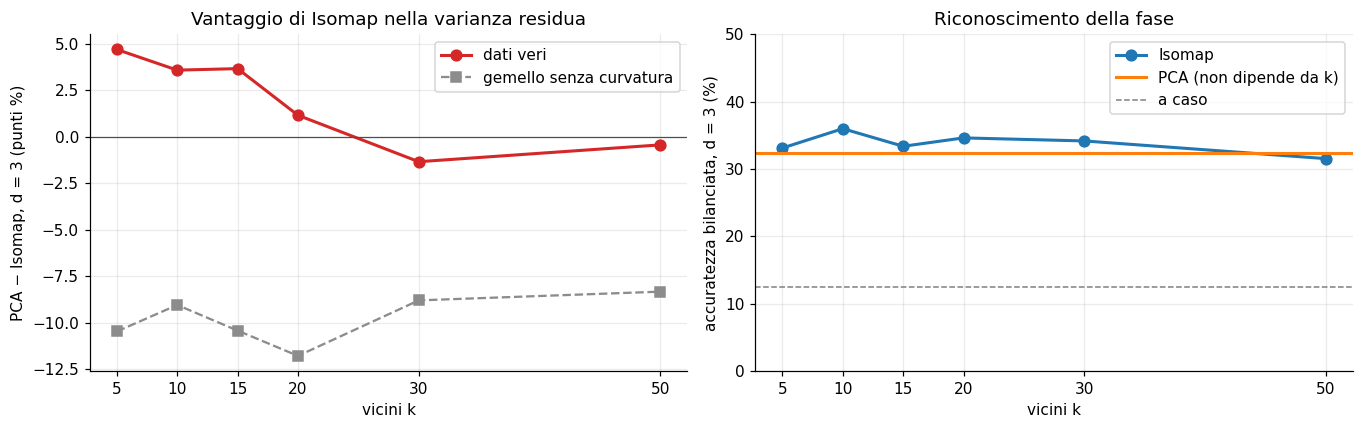

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
ax[0].plot(K_LIST, tab_k["vantaggio Isomap, dati"], "o-", color="C3", lw=2, ms=7, label="dati veri")
ax[0].plot(K_LIST, tab_k["vantaggio Isomap, gemello"], "s--", color="0.55", lw=1.5, ms=7, label="gemello senza curvatura")
ax[0].axhline(0, color="0.3", lw=0.8)
ax[0].set(xlabel="vicini k", ylabel="PCA − Isomap, d = 3 (punti %)", xticks=K_LIST,
          title="Vantaggio di Isomap nella varianza residua")
ax[0].legend()
ax[1].plot(K_LIST, tab_k["fase riconosciuta, Isomap (%)"], "o-", color="C0", lw=2, ms=7, label="Isomap")
ax[1].axhline(tab_k["fase riconosciuta, PCA (%)"].iloc[0], color="C1", lw=2, label="PCA (non dipende da k)")
ax[1].axhline(12.5, color="0.5", ls="--", lw=1, label="a caso")
ax[1].set(xlabel="vicini k", ylabel="accuratezza bilanciata, d = 3 (%)", xticks=K_LIST, ylim=(0, 50),
          title="Riconoscimento della fase")
ax[1].legend()
fig.tight_layout(); fig.savefig(FIGS / "03_sensitivity_k.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Varianza residua.** Il vantaggio di Isomap sui dati è positivo per k = 5-20 e sparisce da 30
  in su. È atteso: con tanti vicini le "strade" diventano scorciatoie in linea d'aria e Isomap si
  avvicina alla PCA (con k = n − 1 coincide, §3.5). Sul gemello Isomap perde sempre (da −8 a
  −12): la distanza tra dati e gemello c'è con ogni k.
- **Riconoscimento della fase.** Isomap sta tra 31.5% e 36.0%, la PCA a 32.4%. Il vantaggio del §6
  (+3.6 punti) è il **più grande** della serie: con gli altri valori di k va da −1 a +2 punti.
  k = 10 era stato scelto prima di vedere questi numeri, ma il vantaggio di Isomap nel riconoscere
  le fasi va riportato per quello che è: **piccolo e dipendente da k**.
- La catena del tempo scende al crescere di k (con più vicini, quelli "dello stesso momento" sono
  una frazione minore), mentre i vicini "stessa fase, altro trial" restano intorno al 23-28%.

### 7.2 · Gli input alternativi

Cambiamo **una scelta alla volta** rispetto alla configurazione principale (smussati σ = 50 ms,
PCA a 25, un bin ogni 5, solo fasi di movimento, k = 10):

| variante | che cosa cambia | perché provarla |
|---|---|---|
| conteggi grezzi | niente smoothing | la trappola 1 del §2 |
| PCA a 10 / a 50 | quante dimensioni tiene la PCA | 25 non deve essere il limite della risposta |
| nessuna PCA | Isomap sui 160 canali | la pre-riduzione cambia il risultato? |
| un bin ogni 2 / ogni 10 | la griglia del sottocampionamento | quanto conta il passo scelto |
| finestra di Theiler | tutti i bin (20 ms), ma vietati come vicini quelli dello stesso trial entro 200 ms | toglie la catena senza buttare punti |
| tutta la sessione | anche `Presentation` e `Intertrial` | i momenti di pausa cambiano la mappa? |
| medie per fase | le 8 traiettorie medie (400 punti) | il segnale "pulito" del notebook 02, §8 |
| fattori GPFA | i 25 fattori della GPFA al posto della PCA | l'input più pulito possibile |

In [24]:
all_bins = np.arange(0, n_bins, STEP)                       # tutta la sessione, un bin ogni 5
alts = {                                                    # ogni variante cambia una sola cosa rispetto a "principale"
    "principale": dict(source=Z, b=bins),
    "conteggi grezzi (PCA a 25)": dict(source=Zc, b=bins),
    "PCA a 10": dict(source=Z, b=bins, K=10),
    "PCA a 50": dict(source=Z, b=bins, K=50),
    "nessuna PCA (160 canali)": dict(source=Z, b=bins, K=None),
    "un bin ogni 2": dict(source=Z, b=bins_all[bins_all % 2 == 0]),
    "un bin ogni 10": dict(source=Z, b=bins_all[bins_all % 10 == 0]),
    "finestra di Theiler ±200 ms (tutti i bin)": dict(source=Z, b=bins_all, forbid_win=CHAIN_BINS),
    "tutta la sessione": dict(source=Z, b=all_bins, fit_bins=np.arange(n_bins)),  # PCA stimata su tutta la sessione
}
rows_alt = {name: evaluate(**kw) for name, kw in alts.items()}

**Le medie per fase** (notebook 02, §8): per ogni fase, la media delle 14-15 ripetizioni della
finestra da 1 s, proiettata sulle stesse 25 direzioni. Sono 8 curve da 50 punti. Qui non ha senso
parlare di trial né di cross-validation: misuriamo solo il vantaggio di Isomap nella varianza
residua.

In [25]:
PSTH = np.concatenate([np.mean([Z25[w["start"]:w["stop"]] for w in windows if w["tag"] == p], axis=0)
                       for p in io.MOVEMENT_PHASES])        # (8 fasi × 50 bin, 25)
iso_avg = isomap_on(PSTH, K_NN, D_EVAL)
rows_alt["medie per fase (400 punti)"] = {
    "punti": len(PSTH),
    "pezzi del grafo": connected_components(kneighbors_graph(PSTH, K_NN), directed=False)[0],
    "vantaggio Isomap, dati": (residual_variance(pdist(PSTH), PCA(D_EVAL).fit_transform(PSTH))
                               - residual_variance(upper(iso_avg.dist_matrix_), iso_avg.embedding_)) * 100}

**I fattori della GPFA.** Stimiamo la GPFA esattamente come nel 02_new (§10): radice dei
conteggi, finestre da 1 s, 25 fattori, 500 iterazioni, fattori ruotati e ordinati per importanza.
Le finestre si sovrappongono, quindi da ogni finestra teniamo solo i bin che appartengono alla sua
fase: ogni bin compare una volta sola. Poi un bin ogni 5, come nella configurazione principale.

Per il riconoscimento delle fasi la stima pulita richiede una GPFA **per ogni blocco** della
cross-validation, stimata sui soli trial di training: i fattori dei trial di test si calcolano poi
con i parametri del training, come `transform` per la PCA. Le 5 GPFA girano in parallelo. In tutto
servono alcuni minuti.

**Il gemello dei fattori.** I surrogati del §5.2 richiedono un segnale continuo, e i fattori
esistono solo dentro le finestre. È però continuo l'**input** della GPFA, la radice dei conteggi:
mescoliamo le fasi di Fourier di quello e gli applichiamo la stessa GPFA, con i parametri stimati
sui dati veri. È ciò che succede per le altre varianti, dove la stessa PCA si applica ai dati veri
e al gemello. Non serve una nuova stima, quindi lo ripetiamo con 5 semi; nella tabella va il seme
0, come per le altre righe. Come controllo, per il seme 0 ristimiamo anche la GPFA direttamente
sul gemello.

In [26]:
import contextlib, logging, os                              # per silenziare i messaggi di avanzamento di elephant
from joblib import Parallel, delayed                        # per stimare le 5 GPFA in parallelo
from elephant.gpfa import gpfa_core                         # le funzioni di calcolo della GPFA (come nel 02_new)
import elephant.utils
elephant.utils.logger.setLevel(logging.ERROR)

X_counts = s.spikes[:, ACTIVE]                              # conteggi grezzi dei 160 canali attivi
Y_sqrt = np.sqrt(X_counts)                                  # la loro radice, su tutta la sessione: è l'input della GPFA

def make_seqs(win_list, Y=None):                            # i dati nel formato di elephant (02_new, §10); Y = input, di norma la radice dei conteggi
    Y = Y_sqrt if Y is None else Y
    return np.array([(w["stop"] - w["start"], Y[w["start"]:w["stop"]].T)  # (bin, canali × bin)
                     for w in win_list], dtype=[("T", int), ("y", "O")])

def fit_gpfa(win_list, Y=None):                             # GPFA con 25 fattori sulle finestre indicate (02_new, §10); Y = input, vedi make_seqs
    np.random.seed(0)                                       # punto di partenza fisso
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        params, _ = gpfa_core.fit(make_seqs(win_list, Y), x_dim=K_PCA, bin_width=20.0, em_max_iters=500, tau_init=100.0)
    return params

def gpfa_per_bin(params, Y=None):                           # i 25 fattori ordinati di ogni bin, calcolati con i parametri dati (Y = input, vedi make_seqs)
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(make_seqs(windows, Y), params, get_ll=False)  # fattori in ogni finestra
        _, orth = gpfa_core.orthonormalize(params, lat)     # ruotati e ordinati per importanza
    out = np.full((n_bins, K_PCA), np.nan)                  # un vettore di 25 fattori per bin (NaN dove non c'è)
    for w, x_ in zip(windows, orth["latent_variable_orth"]):
        own = phase[w["start"]:w["stop"]] == w["tag"]       # i bin della finestra che appartengono alla sua fase
        out[w["start"]:w["stop"]][own] = x_.T[own]
    return out

params_full = fit_gpfa(windows)                             # GPFA su tutte le finestre: per vicini e varianza residua
gp_full = gpfa_per_bin(params_full)                         # i suoi fattori, bin per bin
win_trial = np.full(n_bins, -1)                             # il trial della finestra da cui viene ogni bin
for w in windows:
    own = phase[w["start"]:w["stop"]] == w["tag"]
    win_trial[w["start"]:w["stop"]][own] = w["trial"]
b_gp = np.flatnonzero(~np.isnan(gp_full[:, 0]))             # bin che hanno un valore GPFA
b_gp = b_gp[(b_gp % STEP == 0) & (win_trial[b_gp] == trial[b_gp])]  # un bin ogni 5 (e trial del bin = trial della finestra)
row = evaluate(np.nan_to_num(gp_full), b_gp, K=None, surrogate=False, decode=False)  # vicini e varianza residua (il gemello si calcola qui sotto)
print(f"Punti con i fattori GPFA: {len(b_gp)}, di cui fuori dalle fasi di movimento: {(~MOV[b_gp]).sum()}")
print(pd.Series(phase[b_gp]).value_counts().rename("punti per fase").to_frame().T.to_string())

def isomap_gain(Xp):                                        # vantaggio di Isomap sulla PCA nella varianza residua con d = 3, come in evaluate
    iso_ = isomap_on(Xp, K_NN, D_EVAL)
    return (residual_variance(pdist(Xp), PCA(D_EVAL).fit_transform(Xp))
            - residual_variance(upper(iso_.dist_matrix_), iso_.embedding_)) * 100

gp_twins = [gpfa_per_bin(params_full, phase_randomize(Y_sqrt, seed)) for seed in range(N_SUR)]  # i gemelli: la stessa GPFA sull'input con le fasi di Fourier mescolate
gp_twin = gp_twins[0]                                       # il seme 0, lo stesso usato da evaluate per le altre varianti
gain_tw = [isomap_gain(G_[b_gp]) for G_ in gp_twins]
row["vantaggio Isomap, gemello"] = gain_tw[0]
print(f"Gemello dei fattori GPFA (seme 0): covarianza vs dati veri, correlazione tra gli elementi "
      f"{np.corrcoef(np.cov(gp_full[b_gp].T).ravel(), np.cov(gp_twin[b_gp].T).ravel())[0, 1]:.3f}; catena del tempo "
      f"{neighbor_mix(knn_index(gp_twin[b_gp]), b_gp)['catena del tempo'] * 100:.0f}% (dati veri {row['catena del tempo (%)']:.0f}%)")
Y_tw = phase_randomize(Y_sqrt, 0)                           # controllo: e se la GPFA si ristima direttamente sul gemello (seme 0)?
gain_refit = isomap_gain(gpfa_per_bin(fit_gpfa(windows, Y_tw), Y_tw)[b_gp])
print(f"Vantaggio di Isomap sui {N_SUR} gemelli dei fattori GPFA: da {min(gain_tw):.1f} a {max(gain_tw):.1f}, media {np.mean(gain_tw):.1f} "
      f"(dati veri {row['vantaggio Isomap, dati']:.1f}); con la GPFA ristimata sul gemello: {gain_refit:.1f}")

def gpfa_train(train_trials):                               # GPFA stimata sui soli trial di training; fattori di tutti i bin
    return gpfa_per_bin(fit_gpfa([w for w in windows if w["trial"] in train_trials]))

folds_gp = list(GroupKFold(n_splits=5).split(b_gp, groups=trial[b_gp]))  # 5 blocchi da 3 trial, come al §6
gp_fold = Parallel(n_jobs=5)(delayed(gpfa_train)(np.unique(trial[b_gp[trn]])) for trn, _ in folds_gp)  # le 5 GPFA in parallelo
pred_gp = {m: np.empty(len(b_gp), dtype=object) for m in ("Isomap", "PCA")}
for (trn, tst), G_ in zip(folds_gp, gp_fold):
    Xtr, Xte = G_[b_gp[trn]], G_[b_gp[tst]]
    iso_f, pca_f = Isomap(n_neighbors=K_NN, n_components=D_EVAL).fit(Xtr), PCA(D_EVAL).fit(Xtr)
    for m, (Etr, Ete) in {"Isomap": (iso_f.embedding_, iso_f.transform(Xte)),
                          "PCA": (pca_f.transform(Xtr), pca_f.transform(Xte))}.items():
        pred_gp[m][tst] = KNeighborsClassifier(n_neighbors=10).fit(Etr, phase[b_gp[trn]]).predict(Ete)
row["fase riconosciuta, Isomap (%)"] = balanced_accuracy_score(phase[b_gp], pred_gp["Isomap"]) * 100
row["fase riconosciuta, PCA (%)"] = balanced_accuracy_score(phase[b_gp], pred_gp["PCA"]) * 100
rows_alt["fattori GPFA (d = 25)"] = row

tab_alt = pd.DataFrame(rows_alt).T
display(tab_alt.round(1))

Punti con i fattori GPFA: 872, di cui fuori dalle fasi di movimento: 0
                Reach  Carry  Grasp  Orient2  Release  Orient  Shape  SnapTo
punti per fase    132    131    125      120      112     102     92      58


Gemello dei fattori GPFA (seme 0): covarianza vs dati veri, correlazione tra gli elementi 0.943; catena del tempo 27% (dati veri 26%)


Vantaggio di Isomap sui 5 gemelli dei fattori GPFA: da -10.9 a -8.3, media -9.9 (dati veri -0.7); con la GPFA ristimata sul gemello: -9.8


,punti,pezzi del grafo,catena del tempo (%),"stessa fase, altro trial (%)","vantaggio Isomap, dati","vantaggio Isomap, gemello","fase riconosciuta, Isomap (%)","fase riconosciuta, PCA (%)"
principale,1106.0,1.0,20.4,27.1,3.6,-9.0,36.0,32.4
conteggi grezzi (PCA a 25),1106.0,1.0,1.3,19.5,-6.9,-11.0,21.3,22.0
PCA a 10,1106.0,1.0,14.7,29.2,1.8,-7.3,35.3,32.3
PCA a 50,1106.0,1.0,21.1,24.4,8.6,-8.4,30.3,33.1
nessuna PCA (160 canali),1106.0,1.0,21.0,22.2,0.9,-9.9,31.1,33.4
un bin ogni 2,2754.0,1.0,51.5,17.0,2.6,-8.7,34.4,29.7
un bin ogni 10,554.0,1.0,6.2,29.6,3.6,-12.2,32.4,31.5
finestra di Theiler ±200 ms (tutti i bin),5507.0,NaN,0.0,35.6,3.7,-12.3,36.6,30.4
tutta la sessione,2447.0,1.0,19.3,16.3,-2.4,-8.1,32.8,25.6
medie per fase (400 punti),400.0,3.0,NaN,NaN,-0.8,NaN,NaN,NaN


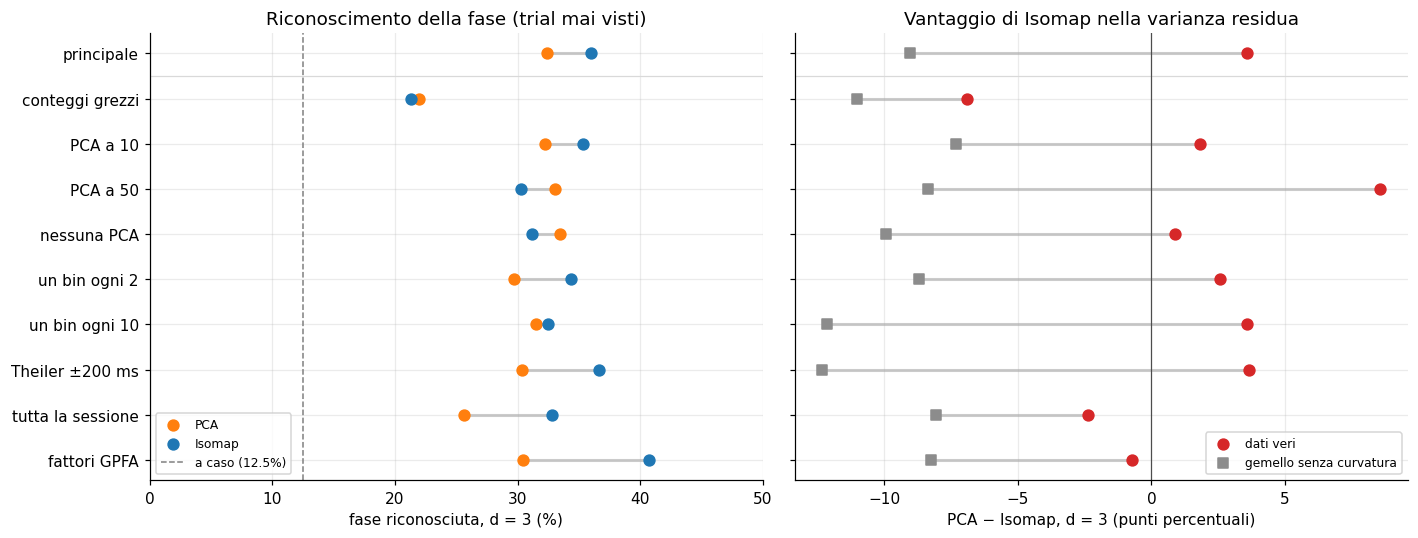

In [27]:
alt = tab_alt.drop(index="medie per fase (400 punti)").astype(float)  # senza le medie per fase: non informative (grafo in 3 pezzi)
short = {"principale": "principale", "conteggi grezzi (PCA a 25)": "conteggi grezzi",
         "PCA a 10": "PCA a 10", "PCA a 50": "PCA a 50", "nessuna PCA (160 canali)": "nessuna PCA",
         "un bin ogni 2": "un bin ogni 2", "un bin ogni 10": "un bin ogni 10",
         "finestra di Theiler ±200 ms (tutti i bin)": "Theiler ±200 ms",
         "tutta la sessione": "tutta la sessione", "fattori GPFA (d = 25)": "fattori GPFA"}
lab = [short[i] for i in alt.index]                         # etichette corte per l'asse
y = np.arange(len(alt))[::-1]                               # dall'alto in basso, nell'ordine della tabella

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for a_, (c1_, c2_) in zip(ax, (("fase riconosciuta, PCA (%)", "fase riconosciuta, Isomap (%)"),
                               ("vantaggio Isomap, gemello", "vantaggio Isomap, dati"))):
    for yi, (_, r) in zip(y, alt.iterrows()):               # un segmento per variante: conta la distanza tra i due punti
        a_.plot([r[c1_], r[c2_]], [yi, yi], color="0.8", lw=2, zorder=1)
    a_.axhline(y[0] - 0.5, color="0.85", lw=0.8)            # separa la configurazione principale dalle varianti
ax[0].scatter(alt["fase riconosciuta, PCA (%)"], y, color="C1", s=50, label="PCA", zorder=2)
ax[0].scatter(alt["fase riconosciuta, Isomap (%)"], y, color="C0", s=50, label="Isomap", zorder=2)
ax[0].axvline(12.5, color="0.5", ls="--", lw=1, label="a caso (12.5%)")
ax[0].set(yticks=y, yticklabels=lab, xlim=(0, 50), xlabel=f"fase riconosciuta, d = {D_EVAL} (%)",
          title="Riconoscimento della fase (trial mai visti)")
ax[0].legend(loc="lower left", fontsize=8)
ax[1].scatter(alt["vantaggio Isomap, dati"], y, color="C3", s=50, label="dati veri", zorder=2)
ax[1].scatter(alt["vantaggio Isomap, gemello"], y, color="0.55", marker="s", s=40,
              label="gemello senza curvatura", zorder=2)
ax[1].axvline(0, color="0.3", lw=0.8)
ax[1].set(xlabel=f"PCA − Isomap, d = {D_EVAL} (punti percentuali)", title="Vantaggio di Isomap nella varianza residua")
ax[1].legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "03_alternatives.png", bbox_inches="tight"); plt.show()

**Lettura**, variante per variante (vantaggio = PCA − Isomap nella varianza residua con d = 3; fasi
= riconoscimento con d = 3, stima pulita).

La figura riassume la tabella. A sinistra il riconoscimento della fase: un segmento per variante,
dalla PCA a Isomap. A destra il vantaggio di Isomap nella varianza residua, sui dati veri e sul
gemello: conta la distanza tra i due punti. Mancano solo le medie per fase (variante non
informativa).

- **Conteggi grezzi**: Isomap peggio della PCA (−6.9 punti) e fasi al 21-22% per entrambi. È la
  trappola 1 del §2: il grafo è fatto di rumore.
- **Dimensioni della PCA iniziale.** Con 10 o 25 dimensioni Isomap riconosce le fasi meglio della
  PCA (+3 / +3.6 punti); con 50 o 160 peggio (−3 / −2). Più direzioni di rumore entrano nel grafo,
  peggio va Isomap, mentre la PCA resta al 32-33%. Il vantaggio nella varianza residua invece non
  segue una tendenza chiara (1.8, 3.6, 8.6, 0.9): è una misura globale, meno legata al
  riconoscimento delle fasi.
- **Passo del sottocampionamento.** Con un bin ogni 2 la catena del tempo torna al 52%; con uno
  ogni 10 scende al 6%, ma restano solo 554 punti. Il vantaggio nella varianza residua è simile
  (2.6-3.7) e sempre molto sopra il gemello.
- **Finestra di Theiler** (tutti i 5507 bin, vietati i vicini dello stesso trial entro 200 ms): la
  catena sparisce per costruzione, i vicini "stessa fase, altro trial" sono i più numerosi (36%), e
  Isomap riconosce le fasi meglio della PCA di 6 punti (36.6% contro 30.4%). È la variante migliore
  tra quelle basate sulla PCA, e porta alla **stessa conclusione** della configurazione
  principale.
- **Tutta la sessione**: i momenti di pausa occupano molti posti tra i vicini ("stessa fase, altro
  trial" scende al 16%). La PCA peggiora molto nel riconoscere le fasi (25.6%), probabilmente
  perché le sue prime direzioni descrivono soprattutto la differenza tra pausa e movimento (non
  l'abbiamo verificato); Isomap regge meglio (32.8%).
- **Medie per fase**: il grafo si spezza in 3 pezzi (alcune curve medie sono troppo lontane dalle
  altre), Isomap deve ricollegarli artificialmente, e il risultato è pari alla PCA.
  Con 8 curve lisce e separate questa variante **non è informativa**.
- **Fattori GPFA**: nella varianza residua Isomap è pari alla PCA (−0.7), ma sui 5 gemelli passati
  per la stessa GPFA perderebbe di 8-11 punti (−9.8 se la GPFA si ristima sul gemello): la distanza
  tra dati e gemello, circa 9 punti, è in linea con le altre varianti. Nel riconoscimento delle
  fasi Isomap ha invece il **vantaggio più grande di tutti**: 40.7% contro 30.5%, con GPFA e Isomap
  stimati solo sui trial di training. I punti sono tutti in fasi di movimento, ma sono 872 e non
  1106: mancano i bin oltre il primo secondo delle fasi lunghe.

Ripulire l'input nel tempo, quindi, non cambia quanta struttura non lineare c'è nelle distanze
globali, ma migliora molto il modo in cui le fasi si dispongono **localmente**. È ciò che guarda
UMAP (parte B, §9).

## 8 · Riepilogo di Isomap

| passo | scelta | perché | alternative (§7) |
|---|---|---|---|
| dati | bin delle fasi di movimento, smussati σ = 50 ms, z-score | gli stessi della PCA del notebook 02; ogni punto ha una fase | tutta la sessione |
| PCA iniziale | 25 dimensioni | toglie il rumore indipendente tra canali; 25 = fattori scelti per la GPFA; più delle dimensioni attese | 10, 50, nessuna (160) |
| sottocampionamento | un bin ogni 5 (100 ms) | rompe la catena del tempo: vicini "dello stesso momento" dal 95% al 20% | un bin ogni 2 o ogni 10; finestra di Theiler |
| vicini k | 10 | valore standard, fissato prima di vedere i risultati | 5, 15, 20, 30, 50 |
| dimensioni per le misure | d = 3 | confronto con le traiettorie del notebook 02 | 1-15 (varianza residua), 2-25 (fasi) |

### Alternative provate in questo notebook

| che cosa | valori provati | effetto | dove |
|---|---|---|---|
| input per il grafo dei vicini | grezzi, smussati, + PCA a 25, + un bin ogni 5 | vicini "stessa fase, altro trial": 16, 2, 5, 27% (a caso 13%) | §2 |
| calcolo a mano | nostro Isomap vs scikit-learn; k = n − 1 vs PCA | identici; con k = n − 1 Isomap è la PCA | §3.4, §3.5 |
| gemello senza curvatura | 5 surrogati a fasi casuali | sui gemelli Isomap perde sempre (−10 punti in media con d = 3); sui dati vince (+3.6) | §5.2 |
| stimatore locale TwoNN | un bin ogni 1 o 5; Theiler 0, 100, 200 ms | stime da 7.5 a 68, uguali sul gemello: non utilizzabile | §5.3 |
| stima del riconoscimento delle fasi | pulita vs scorciatoia | la scorciatoia è ottimista (+5 punti Isomap, +2 PCA) | §7 |
| vicini k | 5, 10, 15, 20, 30, 50 | vantaggio nella varianza residua fino a k = 20; fasi 31.5-36% (PCA 32.4%) | §7.1 |
| dimensioni della PCA iniziale | 10, 25, 50, 160 | Isomap meglio della PCA con 10-25, peggio con 50-160 | §7.2 |
| passo / catena del tempo | ogni 2, 5, 10 bin; Theiler | catena 52, 20, 6, 0%; con Theiler +6 punti sulle fasi | §7.2 |
| quali istanti | fasi di movimento vs tutta la sessione | con la sessione intera la PCA crolla (25.6%), Isomap regge (32.8%) | §7.2 |
| medie per fase | 400 punti | grafo in 3 pezzi, Isomap = PCA: non informativo | §7.2 |
| fattori GPFA come input | 25 fattori, GPFA stimata per blocco | fasi: Isomap 40.7% contro PCA 30.5%, il vantaggio più grande; varianza residua: −0.7 sui dati, −8.3 sul gemello | §7.2 |

### Che cosa abbiamo imparato su Isomap

1. **Conta più come si scelgono i punti che il metodo.** Sui dati smussati il grafo dei vicini è
   una catena del tempo, sui conteggi grezzi è rumore. Serve sottocampionare (o la finestra di
   Theiler) dopo lo smoothing.
2. **C'è struttura non lineare, ma è modesta.** Isomap riproduce le distanze un po' meglio della
   PCA con 1-3 dimensioni (+3.6 punti), mentre su un gemello lineare e gaussiano perderebbe di
   circa 10: la differenza, circa 13 punti, è struttura che un modello lineare gaussiano non
   spiega.
3. **Nessuna dimensione intrinseca piccola nei dati single-trial.** La varianza residua non ha
   gomito, e lo stimatore locale TwoNN su questi dati misura il rumore.
4. **Isomap comprime, non aggiunge.** Con 2-5 coordinate riconosce le fasi un po' meglio della PCA;
   con 10-25 la PCA è meglio. Con la configurazione principale il vantaggio è piccolo e dipende da
   k.
5. **Il vantaggio nel riconoscere le fasi cresce con un input più pulito**: +6 punti con la
   finestra di Theiler, +10 con i fattori GPFA. Ciò che migliora non è globale: con i fattori GPFA
   la distanza dal gemello nella varianza residua non cresce (circa 9 punti, contro 13 della
   configurazione principale). "Locale" va però precisato: sui 25 PC la struttura in più dei
   gemelli è massima in vicinati di 20-50 punti, non tra i vicinissimi (§9.2, vicini conservati al
   variare della scala). Se sia questa la scala che migliora con i fattori GPFA non l'abbiamo
   misurato.
6. **Limiti**: traiettorie seghettate (`transform` a vicini), nessun modello dei dati, distanze
   geodesiche molto deformate dal rumore (autovalori negativi pari al 63% dei positivi, contro il
   4% del foglio arrotolato).

> **Regola per la tesi.** Un risultato di Isomap va riportato con tutte le scelte che lo producono
> e con il suo termine di confronto, per esempio: *"Isomap (k = 10) su 25 PC dei firing rate
> smussati (σ = 50 ms), un punto ogni 100 ms nelle fasi di movimento: varianza residua con 3
> dimensioni 0.38 contro 0.41 della PCA; su surrogati a fasi casuali Isomap è sempre peggiore della
> PCA (−10 punti in media)"*.

## 9 · Parte B: UMAP, in breve

UMAP (McInnes et al. 2018) parte dallo stesso grafo dei vicini di Isomap (§2), ma poi fa una cosa
diversa. Isomap misura le distanze lungo il grafo e cerca una mappa che le riproduca **tutte**,
anche tra punti lontani. UMAP chiede solo che **i vicini restino vicini** e che i non vicini non
finiscano accanto. È come disporre gli invitati a una festa in modo che ognuno abbia intorno i
propri amici, senza curarsi di quanto distano tra loro i vari gruppi.

Tre conseguenze, da tenere presenti prima di guardare qualunque mappa:

- **Le distanze nella mappa non si interpretano**: né quelle tra gruppi lontani, né la grandezza
  dei gruppi. Per questo la varianza residua del §5 qui non ha senso, e UMAP non dice niente sulla
  dimensione intrinseca.
- **Il risultato dipende dal caso**: la mappa si aggiusta con passi casuali. Fissiamo il seme e
  ripetiamo le misure principali (riconoscimento delle fasi, vicini conservati sui dati veri, isole
  di `Shape`) con 5 semi diversi. Le mappe del §9.2, i gemelli e le traiettorie del §9.4 usano un
  solo seme.
- **Due parametri**: `n_neighbors` (quanti vicini per punto: è il k di Isomap, e usiamo lo stesso
  valore, 10) e `min_dist` (quanto i punti possono ammassarsi nella mappa; valore standard 0.1).

Questa parte è volutamente breve. Usa gli stessi punti, gli stessi blocchi di cross-validation e
gli stessi gemelli della parte A, e risponde a quattro domande:

1. Con 2-3 coordinate UMAP riconosce le fasi meglio di Isomap e della PCA? (§9.1)
2. Che cosa disegna UMAP su una nuvola senza struttura? (§9.2)
3. Quanto dipende il risultato dal seme e dai parametri? (§9.3)
4. Come sono le traiettorie single-trial? (§9.4)

### 9.1 · Le fasi si riconoscono meglio?

Stessa misura del §6: classificatore a 10 vicini, accuratezza bilanciata (a caso 12.5%),
cross-validation per trial con la mappa stimata **solo sui trial di training**. La proviamo su due
input: i 25 PC della configurazione principale e i 25 fattori GPFA, che al §7.2 erano l'input
migliore.

Aggiungiamo un termine di confronto: il classificatore **senza nessuna mappa**, direttamente sulle
25 dimensioni. Lo chiamiamo **tetto**: una mappa a 2-3 dimensioni costruita dal grafo dei vicini
può conservare l'informazione che i vicini contengono, non ci aspettiamo che ne aggiunga. È un
termine di confronto, non un limite matematico. Per i 25 PC è la "PCA con d = 25" del §6 (42.2%).

In [28]:
from umap import UMAP                                       # UMAP (pacchetto umap-learn)

def folds_pca(source, b):                                   # i 5 blocchi del §6: la PCA a 25 vede solo i trial di training
    out = []
    for trn, tst in GroupKFold(n_splits=5).split(b, groups=trial[b]):
        pca_f = PCA(K_PCA).fit(source[bins_all[np.isin(trial[bins_all], np.unique(trial[b[trn]]))]])
        out.append((pca_f.transform(source[b[trn]]), pca_f.transform(source[b[tst]]), trn, tst))
    return out

INPUTS_U = {                                                # i due input: (bin usati come punti, [(training, test, indici) per blocco])
    "25 PC (principale)": (bins, folds_pca(Z, bins)),       # stessi punti e stessi blocchi del §6
    "25 fattori GPFA": (b_gp, [(G_[b_gp[trn]], G_[b_gp[tst]], trn, tst)  # le 5 GPFA per blocco del §7.2
                               for (trn, tst), G_ in zip(folds_gp, gp_fold)]),
}

def decode_map(inp, embed):                                 # accuratezza bilanciata (%) con una mappa qualsiasi, stima pulita
    b, folds = inp
    pred = np.empty(len(b), dtype=object)
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)                          # la mappa si stima sul training; i punti di test si proiettano
        pred[tst] = KNeighborsClassifier(n_neighbors=10).fit(Etr, phase[b[trn]]).predict(Ete)
    return balanced_accuracy_score(phase[b], pred) * 100

def emb_umap(d, n_neighbors=K_NN, min_dist=0.1, seed=0):    # UMAP: n_jobs=1 perché con un seme fisso gira comunque su un core
    def f(Xtr, Xte):
        u = UMAP(n_neighbors=n_neighbors, n_components=d, min_dist=min_dist, random_state=seed, n_jobs=1).fit(Xtr)
        return u.embedding_, u.transform(Xte)
    return f

def emb_isomap(d):                                          # Isomap come al §6
    def f(Xtr, Xte):
        i_ = Isomap(n_neighbors=K_NN, n_components=d).fit(Xtr)
        return i_.embedding_, i_.transform(Xte)
    return f

def emb_pca(d):                                             # PCA come al §6
    def f(Xtr, Xte):
        p_ = PCA(d).fit(Xtr)
        return p_.transform(Xtr), p_.transform(Xte)
    return f

def emb_none(Xtr, Xte):                                     # nessuna mappa: il classificatore lavora sulle 25 dimensioni
    return Xtr, Xte

SEEDS = range(5)                                            # i passi con cui UMAP aggiusta la mappa sono casuali: lo ripetiamo con 5 semi

def umap_seeds(name, **kw):                                 # le 5 accuratezze (una per seme) di una configurazione di UMAP
    return np.array(Parallel(n_jobs=5)(delayed(decode_map)(INPUTS_U[name], emb_umap(seed=sd, **kw)) for sd in SEEDS))

rows_u = {}
for name, inp in INPUTS_U.items():
    col = {f"PCA, d = {d}": f"{decode_map(inp, emb_pca(d)):.1f}" for d in (2, 3)}
    col.update({f"Isomap, d = {d}": f"{decode_map(inp, emb_isomap(d)):.1f}" for d in (2, 3)})
    for d in (2, 3):
        a_ = umap_seeds(name, d=d)
        col[f"UMAP, d = {d} (media dei 5 semi; min-max)"] = f"{a_.mean():.1f} ({a_.min():.1f}-{a_.max():.1f})"
    col["nessuna mappa, 25 dimensioni (il tetto)"] = f"{decode_map(inp, emb_none):.1f}"
    rows_u[name] = col
tab_u = pd.DataFrame(rows_u)
display(tab_u)
print(f"Tetto dei 25 PC sugli stessi {len(b_gp)} punti dei fattori GPFA: "
      f"{decode_map((b_gp, folds_pca(Z, b_gp)), emb_none):.1f}%")

,25 PC (principale),25 fattori GPFA
"PCA, d = 2",26.0,31.1
"PCA, d = 3",32.4,30.5
"Isomap, d = 2",31.8,37.3
"Isomap, d = 3",36.0,40.7
"UMAP, d = 2 (media dei 5 semi; min-max)",41.2 (40.4-42.3),50.6 (49.9-52.0)
"UMAP, d = 3 (media dei 5 semi; min-max)",42.6 (41.9-43.2),50.5 (49.9-51.0)
"nessuna mappa, 25 dimensioni (il tetto)",42.2,50.8


Tetto dei 25 PC sugli stessi 872 punti dei fattori GPFA: 43.0%


**Lettura.**

- **UMAP arriva al tetto con 2-3 coordinate**: con d = 3, 42.6% contro 42.2% sui 25 PC e 50.5%
  contro 50.8% sui fattori GPFA. Isomap con d = 3 si ferma a 36.0% e 40.7%, la PCA a 32.4% e
  30.5%.
- **Non lo supera in modo apprezzabile.** Le medie stanno entro circa mezzo punto dal tetto, meno
  della differenza tra un seme e l'altro. UMAP non trova informazione nuova: mette in 2-3
  coordinate quasi tutta quella che i vicini contengono in 25 dimensioni. Vale la conclusione del
  §6 su Isomap (comprime, non aggiunge), solo che UMAP comprime molto meglio.
- **In parte è atteso per costruzione.** `transform` di UMAP colloca un punto nuovo in mezzo ai
  suoi vicini di training in 25 dimensioni. Il classificatore a vicini nella mappa interroga quindi
  punti della stessa zona: non gli stessi 10 (al §9.2 vedremo che ne restano circa 4 su 10), ma
  votano in media allo stesso modo. La misura dice che la mappa conserva l'informazione sulle fasi
  contenuta nei vicinati, non che UMAP ha scoperto una forma.
- **Il tetto dipende dall'input**: 42.2% sui 25 PC, 50.8% sui fattori GPFA. I due input non hanno
  gli stessi punti (1106 contro 872, perché i fattori GPFA esistono solo nel primo secondo di ogni
  fase, §7.2), ma la differenza resta a parità di punti: sugli stessi 872 il tetto dei 25 PC è
  43.0%. È la lezione 1 di Isomap (§8): conta come si preparano i punti.
- **I semi contano poco**: tra il seme migliore e il peggiore ci sono 1-2 punti.

**Un controllo sull'input.** Se UMAP conserva solo l'informazione che i vicini contengono, con un
input più rumoroso deve scendere insieme al tetto. Lo proviamo senza PCA, sugli stessi 1106 punti
e sugli stessi blocchi: i 160 canali smussati e i conteggi grezzi del §2.

In [29]:
def folds_plain(src):                                       # nessuna PCA: i dati entrano così come sono, stessi blocchi del §6
    return [(src[bins[trn]], src[bins[tst]], trn, tst)
            for trn, tst in GroupKFold(n_splits=5).split(bins, groups=trial[bins])]

for name, src in {"smussati, 160 canali (senza PCA)": Z, "conteggi grezzi, 160 canali": Zc}.items():
    inp = (bins, folds_plain(src))
    a_ = np.array([decode_map(inp, emb_umap(d=3, seed=sd)) for sd in SEEDS])   # 5 semi
    print(f"{name}: UMAP d = 3 {a_.mean():.1f}% ({a_.min():.1f}-{a_.max():.1f}) | "
          f"senza mappa {decode_map(inp, emb_none):.1f}%")

smussati, 160 canali (senza PCA): UMAP d = 3 40.2% (39.3-40.9) | senza mappa 40.7%


conteggi grezzi, 160 canali: UMAP d = 3 17.0% (16.1-18.7) | senza mappa 16.8%


**Lettura.** UMAP scende insieme al tetto: 40.2% contro 40.7% sui 160 canali smussati, 17.0%
contro 16.8% sui conteggi grezzi (a caso 12.5%). Lo smoothing conta molto (da 17.0% a 40.2%), la
PCA a 25 sposta poco (da 40.2% a 42.6%). Per salire bisogna alzare il tetto, cioè dare a UMAP un
input più pulito, come i fattori GPFA (50.5%).

### 9.2 · Che cosa disegna UMAP su una nuvola senza struttura?

Il rischio noto delle mappe a 2 dimensioni come UMAP è che deformino distanze e vicinati, e che
forme e gruppi nella mappa siano in parte un prodotto del metodo (Chari & Pachter 2023). Per
controllarlo usiamo i **gemelli senza curvatura** del §5.2: stessa covarianza e stessa catena del
tempo dei dati veri, ma nessuna struttura legata alle fasi.

Prima guardiamo le mappe in 2 dimensioni: in alto i dati veri e i fattori GPFA, in basso i 5
gemelli dei 25 PC e il gemello dei fattori GPFA (§7.2). Qui UMAP è stimato su tutti i punti e con
un solo seme: va bene per guardare, non per misurare (è la scorciatoia del §7). Nei gemelli le fasi
non esistono: ogni punto ha il colore del bin corrispondente nei dati veri, solo per confronto.

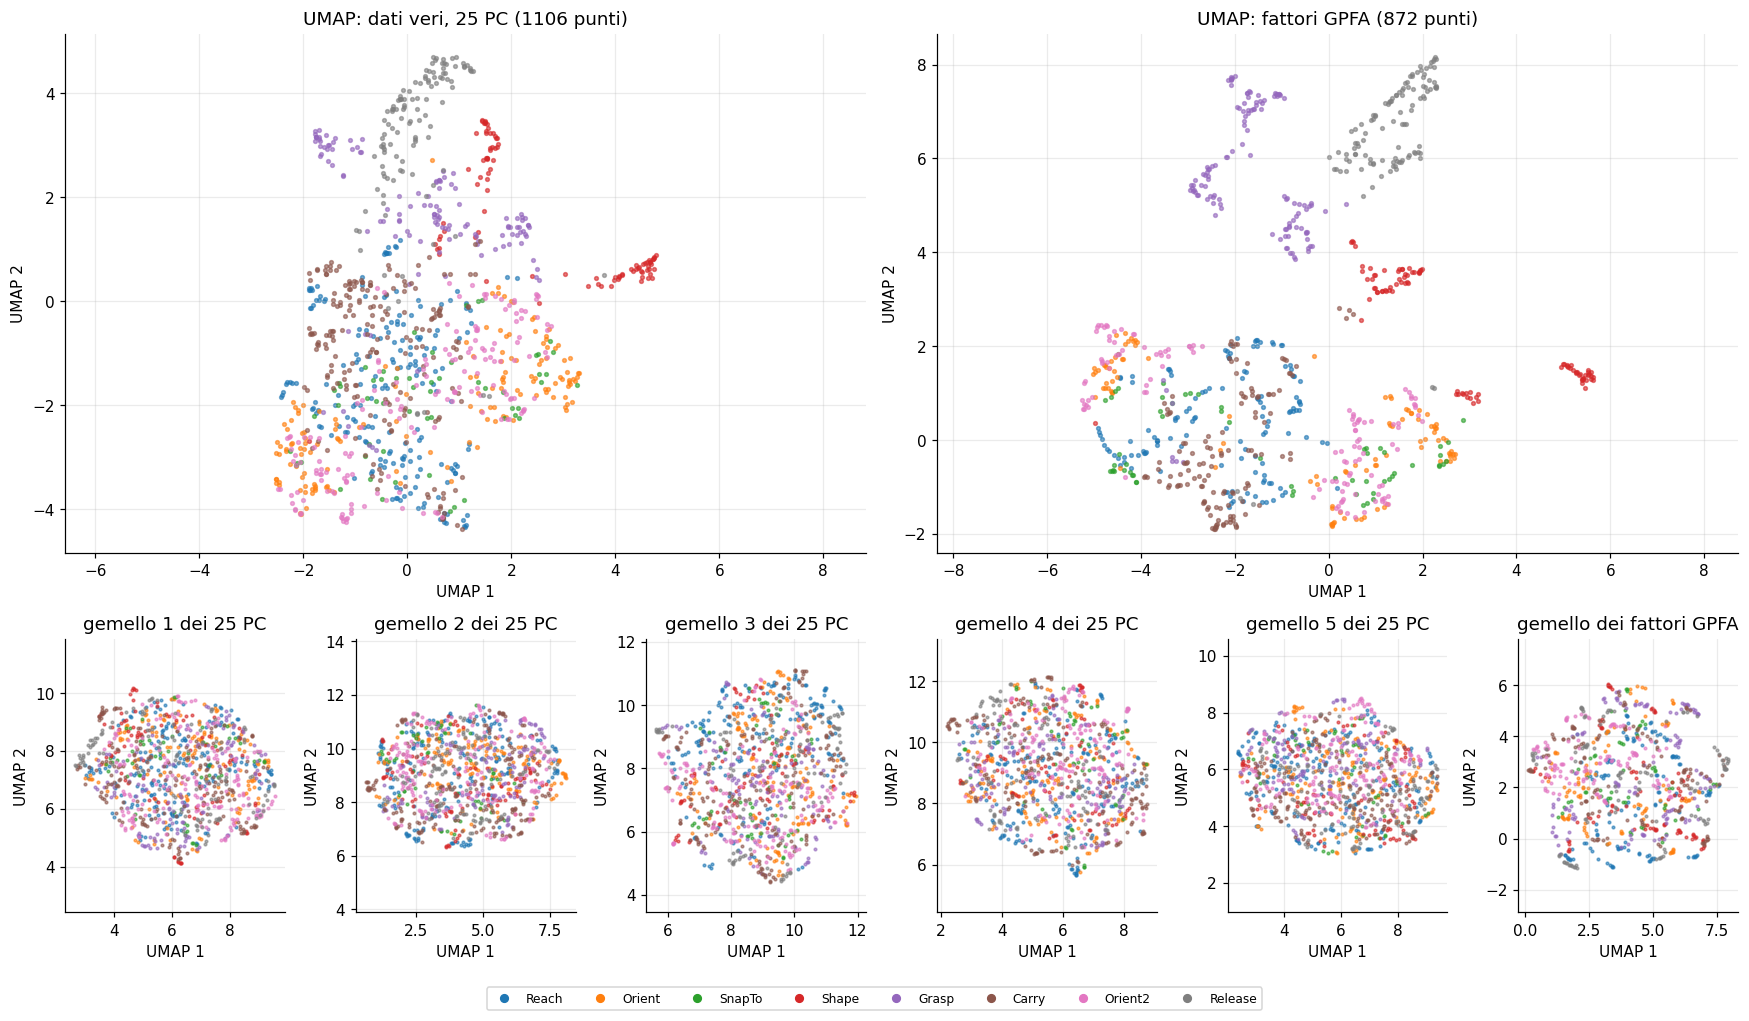

In [30]:
def umap_fit(Xp, d, seed=0):                                # UMAP stimato su tutti i punti dati: per guardare la mappa, non per misurare
    return UMAP(n_neighbors=K_NN, n_components=d, random_state=seed, n_jobs=1).fit_transform(Xp)

def draw_map(a_, Xp, ph_, title, size=6):                   # una mappa UMAP in 2 dimensioni (seme 0), un colore per fase
    Yu = umap_fit(Xp, 2)
    for p in io.MOVEMENT_PHASES:
        m = ph_ == p
        a_.scatter(Yu[m, 0], Yu[m, 1], s=size, alpha=0.6, color=io.PHASE_COLORS[p])
    a_.set(title=title, xlabel="UMAP 1", ylabel="UMAP 2")
    a_.set_aspect("equal", adjustable="datalim")            # stessa scala sui due assi

fig = plt.figure(figsize=(16, 9.2))
gs = fig.add_gridspec(2, 12, height_ratios=(1.9, 1))        # in alto due mappe grandi, in basso sei piccole
draw_map(fig.add_subplot(gs[0, :6]), X, ph, f"UMAP: dati veri, 25 PC ({len(X)} punti)")
draw_map(fig.add_subplot(gs[0, 6:]), gp_full[b_gp], phase[b_gp],          # GPFA stimata su tutte le finestre (§7.2)
         f"UMAP: fattori GPFA ({len(b_gp)} punti)")
for i, Xs in enumerate(sur):                                # i 5 gemelli del §5.2: lì le fasi non esistono, i colori servono solo da confronto
    draw_map(fig.add_subplot(gs[1, 2 * i:2 * i + 2]), Xs, ph, f"gemello {i + 1} dei 25 PC", size=3)
draw_map(fig.add_subplot(gs[1, 10:]), gp_twin[b_gp], phase[b_gp], "gemello dei fattori GPFA", size=3)  # il gemello del §7.2
handles = [plt.Line2D([], [], color=io.PHASE_COLORS[p], marker="o", ls="", ms=5, label=p) for p in io.MOVEMENT_PHASES]
fig.legend(handles=handles, ncol=8, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIGS / "03_umap_maps.png", bbox_inches="tight"); plt.show()

Poi una misura. Per ogni punto prendiamo i suoi 10 vicini in 25 dimensioni e contiamo quanti
restano tra i suoi 10 vicini nella mappa: sono i **vicini conservati**. È la misura locale che
corrisponde alla varianza residua del §5 e, come al §5.2, conta la **differenza tra dati e
gemelli**. Sui dati veri ripetiamo UMAP con 5 semi; per i gemelli usiamo i 5 gemelli, con un seme
ciascuno. Del vantaggio di UMAP sulla PCA riportiamo media, minimo e massimo.

In [31]:
def kept_neighbors(Xp, Y, k=K_NN):                          # dei k vicini di ogni punto in 25 dimensioni, quanti restano tra i k vicini nella mappa (%)
    a_, b_ = knn_index(Xp, k), knn_index(Y, k)
    return np.mean([len(np.intersect1d(a_[i], b_[i])) for i in range(len(a_))]) / k * 100

def kept_all(Xp, d, seed=0):                                # vicini conservati dai tre metodi sugli stessi punti
    return {"PCA": kept_neighbors(Xp, PCA(d).fit_transform(Xp)),
            "Isomap": kept_neighbors(Xp, Isomap(n_neighbors=K_NN, n_components=d).fit_transform(Xp)),
            "UMAP": kept_neighbors(Xp, umap_fit(Xp, d, seed))}

rows_kn = {}
for d in (2, 3):
    runs = {f"d = {d}, dati veri (5 semi)": pd.DataFrame([kept_all(X, d, sd) for sd in SEEDS]),   # dati veri: 5 semi di UMAP
            f"d = {d}, gemelli (5)": pd.DataFrame([kept_all(Xs, d) for Xs in sur])}               # i 5 gemelli del §5.2, seme 0
    for label, r_ in runs.items():
        gap = r_["UMAP"] - r_["PCA"]                        # vantaggio di UMAP sulla PCA in ogni ripetizione
        rows_kn[label] = {**r_.mean(), "UMAP − PCA": gap.mean(), "UMAP − PCA, minimo": gap.min(),
                          "UMAP − PCA, massimo": gap.max(), "UMAP / PCA": r_["UMAP"].mean() / r_["PCA"].mean()}
tab_kn = pd.DataFrame(rows_kn).T
display(tab_kn.round(1))

,PCA,Isomap,UMAP,UMAP − PCA,"UMAP − PCA, minimo","UMAP − PCA, massimo",UMAP / PCA
"d = 2, dati veri (5 semi)",7.0,8.8,33.8,26.8,26.4,27.1,4.8
"d = 2, gemelli (5)",5.7,6.0,26.3,20.6,19.5,21.4,4.6
"d = 3, dati veri (5 semi)",12.0,14.6,38.6,26.6,26.5,26.8,3.2
"d = 3, gemelli (5)",9.8,10.3,32.6,22.8,22.4,23.3,3.3


**Lettura.**

- **Sui gemelli UMAP non disegna isole.** In tutti e 6 (i 5 dei 25 PC e quello dei fattori GPFA)
  la mappa è una macchia unica con i colori mescolati. Restano solo brevi filamenti di pochi
  punti, probabilmente bin vicini nel tempo dello stesso trial (non l'abbiamo verificato). Nel
  gemello dei fattori GPFA sono più numerosi, come ci si aspetta da fattori lisci nel tempo, ma
  nessuna fase forma un'isola. Covarianza e catena del tempo, da sole, non bastano quindi a
  produrre le isole dei dati veri.
- **Il controllo ha due limiti.** Il gemello è gaussiano (§5.2): non esclude che UMAP esageri la
  separazione tra gruppi che in 25 dimensioni sono collegati. E dei 5 gemelli dei fattori GPFA
  (§7.2) qui ne guardiamo uno solo, il seme 0.
- **Nei dati veri si staccano le fasi della mano**, le stesse del §4: `Shape`, `Release` e
  `Grasp`. Con i fattori GPFA le isole sono più nette. Le fasi del braccio (`Reach`, `Orient`,
  `SnapTo`, `Carry`, `Orient2`) restano un unico gruppo mescolato in entrambe le mappe.
- **UMAP conserva molti più vicini**: con d = 3 il 38.6%, contro il 12.0% della PCA e il 14.6% di
  Isomap. Ma lo fa anche sui gemelli (32.6% contro 9.8%): in entrambi i casi circa 3 volte la PCA.
  Il vantaggio è quindi quasi tutto una proprietà del metodo, che vale anche per una nuvola
  gaussiana senza struttura.
- **In punti, il vantaggio è un po' più grande sui dati**: con d = 3, 26.6 (tra i semi 26.5-26.8)
  contro 22.8 (tra i gemelli 22.4-23.3); con d = 2, 26.8 contro 20.6. Gli intervalli non si
  toccano, ma la differenza è piccola, e come rapporto sparisce.
- È coerente con il §5.2, ma qui manca il cambio di segno che là rendeva il controllo decisivo:
  anche la PCA conserva qualche vicino in più sui dati (12.0% contro 9.8%).

### Vicini conservati al variare della scala

La misura qui sopra conta i vicini conservati tra i **10** più vicini. Ma 10 è una scelta: con un
numero più piccolo si guarda una scala più locale, con uno più grande una scala più globale. È la
domanda lasciata aperta dal §7.2: **a quale scala** i dati veri hanno struttura in più dei gemelli,
locale o globale?

Ci sono due k diversi, da non confondere:

- il **k del metodo** (`n_neighbors` di UMAP e di Isomap): quanti vicini usa il metodo per
  costruire la mappa. Resta fisso a 10 (`K_NN`), come in tutto il notebook;
- il **k della misura**: quanti vicini contiamo per dire se la mappa li ha conservati. È l'unico
  che facciamo variare: 5, 10, 20, 50, 100, 200. Su 1106 punti vuol dire da meno dell'1% al 18%
  dei punti.

Le mappe sono a 3 dimensioni e si stimano una volta sola per ogni insieme di punti: i dati veri
(UMAP con 5 semi) e i 5 gemelli (un seme ciascuno), come nella misura qui sopra. Non c'è un
classificatore né un test, quindi le mappe si stimano su tutti i punti.

Aggiungiamo un riferimento, la **mappa a caso**: se i vicini nella mappa fossero scelti a caso, ne
resterebbero k su n − 1. Questo valore sale con k anche senza nessuna struttura (0.5% con k = 5,
18% con k = 200).

k della misura,5,10,20,50,100,200
"PCA, dati veri",8.9,12.0,16.8,24.6,32.5,44.1
"PCA, gemelli (media dei 5; min-max)",7.3 (6.8-7.8),9.8 (9.3-10.1),13.7 (13.2-14.5),21.8 (21.2-22.7),31.3 (30.5-32.5),44.5 (43.6-45.7)
"PCA, dati − gemelli",+1.6,+2.2,+3.1,+2.8,+1.2,-0.3
"Isomap, dati veri",10.7,14.6,19.0,25.9,32.7,42.8
"Isomap, gemelli (media dei 5; min-max)",7.4 (7.3-7.6),10.3 (10.1-10.5),13.6 (13.1-14.0),20.3 (19.5-21.2),28.3 (27.2-29.1),40.0 (38.6-41.2)
"Isomap, dati − gemelli",+3.3,+4.2,+5.4,+5.6,+4.5,+2.8
"UMAP, dati veri (media dei 5 semi; min-max)",39.6 (39.3-39.8),38.6 (38.5-38.8),36.1 (35.7-36.2),36.3 (36.2-36.4),38.6 (38.4-38.7),44.6 (44.6-44.7)
"UMAP, gemelli (media dei 5; min-max)",37.6 (36.6-38.6),32.6 (32.1-33.3),27.9 (27.0-28.4),27.0 (26.6-27.5),30.8 (30.4-31.7),39.3 (38.6-40.7)
"UMAP, dati − gemelli",+2.0,+6.0,+8.1,+9.3,+7.8,+5.4
mappa a caso,0.5,0.9,1.8,4.5,9.0,18.1


k della misura,5,10,20,50,100,200
"UMAP − PCA, dati veri",30.7,26.6,19.3,11.7,6.1,0.5
"UMAP − PCA, gemelli",30.2,22.8,14.2,5.2,-0.5,-5.2
"UMAP − Isomap, dati veri",29.0,24.1,17.1,10.3,5.8,1.8
"UMAP − Isomap, gemelli",30.2,22.3,14.3,6.7,2.5,-0.7
"UMAP / PCA, dati veri",4.5,3.2,2.1,1.5,1.2,1.0
"UMAP / PCA, gemelli",5.1,3.3,2.0,1.2,1.0,0.9


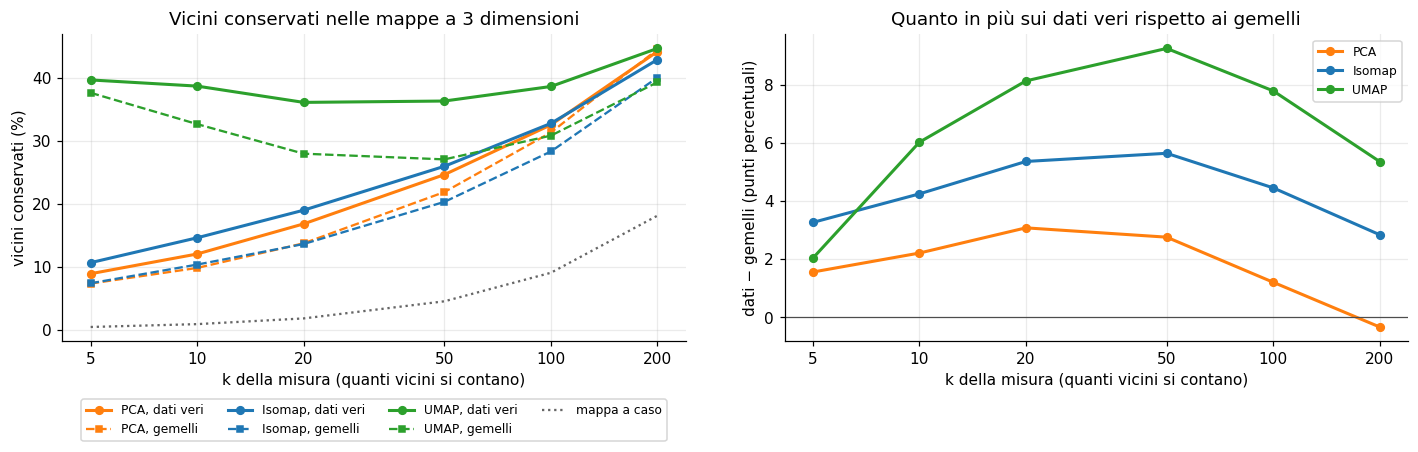

In [32]:
K_EVAL = (5, 10, 20, 50, 100, 200)                          # k della MISURA: quanti vicini si contano (il k del METODO resta K_NN = 10)
METHODS = ("PCA", "Isomap", "UMAP")                         # i tre metodi, nell'ordine delle tabelle del §9.2

def maps3(Xp, seeds=(0,)):                                  # le tre mappe a 3 dimensioni di un insieme di punti, stimate una volta sola
    return {"PCA": [PCA(D_EVAL).fit_transform(Xp)],
            "Isomap": [Isomap(n_neighbors=K_NN, n_components=D_EVAL).fit_transform(Xp)],
            "UMAP": [umap_fit(Xp, D_EVAL, sd) for sd in seeds]}  # UMAP: una mappa per seme

def kept_by_k(Xp, maps):                                    # per ogni metodo: vicini conservati (%), una riga per mappa e una colonna per k
    return {m: np.array([[kept_neighbors(Xp, Y, k) for k in K_EVAL] for Y in Ys]) for m, Ys in maps.items()}

kept_data = kept_by_k(X, maps3(X, SEEDS))                   # dati veri: UMAP con i 5 semi (5 righe), PCA e Isomap una mappa sola (1 riga)
kept_twin = [kept_by_k(Xs, maps3(Xs)) for Xs in sur]        # i 5 gemelli del §5.2, un seme di UMAP per gemello
kept_sur = {m: np.concatenate([kt[m] for kt in kept_twin]) for m in METHODS}  # per metodo: 5 righe (i gemelli) × 6 colonne (i k)
chance_k = np.array(K_EVAL) / (len(X) - 1) * 100            # "mappa a caso": con vicini scelti a caso nella mappa ne resterebbero k su n − 1

def mean_range(A):                                          # "media (minimo-massimo)" per ogni k, da una matrice ripetizioni × k
    return [f"{a.mean():.1f} ({a.min():.1f}-{a.max():.1f})" for a in A.T]

rows_ke = {}
for m in METHODS:
    d_, g_ = kept_data[m], kept_sur[m]                      # dati veri e gemelli di questo metodo
    if len(d_) > 1:                                         # UMAP: 5 semi, quindi media e minimo-massimo
        rows_ke[f"{m}, dati veri (media dei 5 semi; min-max)"] = mean_range(d_)
    else:                                                   # PCA e Isomap: una mappa sola
        rows_ke[f"{m}, dati veri"] = [f"{v:.1f}" for v in d_[0]]
    rows_ke[f"{m}, gemelli (media dei 5; min-max)"] = mean_range(g_)
    rows_ke[f"{m}, dati − gemelli"] = [f"{v:+.1f}" for v in d_.mean(0) - g_.mean(0)]  # differenza tra le due medie, in punti percentuali
rows_ke["mappa a caso"] = [f"{v:.1f}" for v in chance_k]
tab_ke = pd.DataFrame(rows_ke, index=pd.Index(K_EVAL, name="k della misura")).T
display(tab_ke)

u_d, u_g = kept_data["UMAP"].mean(0), kept_sur["UMAP"].mean(0)  # UMAP: media dei semi (dati) e dei gemelli, per ogni k
tab_gain = pd.DataFrame({                                   # il vantaggio di UMAP sugli altri due metodi, per ogni k
    "UMAP − PCA, dati veri": u_d - kept_data["PCA"][0], "UMAP − PCA, gemelli": u_g - kept_sur["PCA"].mean(0),
    "UMAP − Isomap, dati veri": u_d - kept_data["Isomap"][0], "UMAP − Isomap, gemelli": u_g - kept_sur["Isomap"].mean(0),
    "UMAP / PCA, dati veri": u_d / kept_data["PCA"][0], "UMAP / PCA, gemelli": u_g / kept_sur["PCA"].mean(0),
}, index=pd.Index(K_EVAL, name="k della misura")).T
display(tab_gain.round(1))

COL_M = {"PCA": "C1", "Isomap": "C0", "UMAP": "C2"}         # un colore per metodo (PCA e Isomap come ai §5 e §6)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for m in METHODS:
    ax[0].plot(K_EVAL, kept_data[m].mean(0), "o-", color=COL_M[m], lw=2, ms=5, label=f"{m}, dati veri")       # linea piena: dati veri
    ax[0].plot(K_EVAL, kept_sur[m].mean(0), "s--", color=COL_M[m], lw=1.5, ms=4, label=f"{m}, gemelli")       # tratteggiata: media dei 5 gemelli
    ax[1].plot(K_EVAL, kept_data[m].mean(0) - kept_sur[m].mean(0), "o-", color=COL_M[m], lw=2, ms=5, label=m)  # quanto in più sui dati
ax[0].plot(K_EVAL, chance_k, ":", color="0.4", lw=1.5, label="mappa a caso")
ax[1].axhline(0, color="0.3", lw=0.8)                       # sopra lo zero: sui dati veri si conservano più vicini che sui gemelli
ax[0].set(xscale="log", xticks=K_EVAL, xticklabels=K_EVAL, xlabel="k della misura (quanti vicini si contano)",
          ylabel="vicini conservati (%)", title=f"Vicini conservati nelle mappe a {D_EVAL} dimensioni")
ax[1].set(xscale="log", xticks=K_EVAL, xticklabels=K_EVAL, xlabel="k della misura (quanti vicini si contano)",
          ylabel="dati − gemelli (punti percentuali)", title="Quanto in più sui dati veri rispetto ai gemelli")
ax[0].minorticks_off(); ax[1].minorticks_off()              # solo i tick sui valori di K_EVAL
ax[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17))  # legenda sotto il grafico, per non coprire le curve
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "03_kept_vs_k.png", bbox_inches="tight"); plt.show()

**Lettura.** Con k = 10 si ritrovano i numeri della tabella precedente.

- **Il vantaggio di UMAP è massimo alla scala più piccola e sparisce alla più grande.** Sui dati
  veri, con k = 5 UMAP conserva 30.7 punti più della PCA e 29.0 più di Isomap. Il vantaggio scende
  a ogni passo (con k = 50: 11.7 e 10.3) e con k = 200 è quasi nullo: +0.5 sulla PCA, +1.8 su
  Isomap. Sui gemelli lo perde prima: da k = 100 UMAP conserva meno vicini della PCA (−0.5, poi
  −5.2 con k = 200). UMAP tiene il 36-40% dei vicini da k = 5 a k = 100, mentre PCA e Isomap
  salgono con k (dal 9-11% al 43-44%): è una mappa che conserva i vicinati piccoli, come dice il
  suo `n_neighbors` = 10, non la disposizione d'insieme.
- **La differenza tra dati e gemelli è massima a una scala intermedia, per tutti e tre i
  metodi.** UMAP: +9.3 punti con k = 50 (+8.1 con k = 20, +7.8 con k = 100). Isomap: +5.6 con
  k = 50 (+5.4 con k = 20). PCA: +3.1 con k = 20. Alla scala più piccola è minore (k = 5: UMAP
  +2.0, Isomap +3.3, PCA +1.6) e alla più grande scende di nuovo (k = 200: UMAP +5.4, Isomap
  +2.8, PCA −0.3, cioè nulla).
- **Quanto sono netti questi numeri.** Per UMAP il profilo è netto: con k = 5 i gemelli
  conservano il 36.6-38.6% dei vicini contro il 39.6% dei dati, con k = 50 il 26.6-27.5% contro
  il 36.3%. Per Isomap e PCA la forma è la stessa, ma tra il massimo e gli estremi ci sono solo
  1.5-3.5 punti, poco più dello scarto tra un gemello e l'altro (di solito 1-2 punti). In assoluto
  le differenze restano piccole, al massimo 9 punti su 100. E valgono i limiti di sempre: i
  gemelli sono gaussiani (§5.2) e per ognuno c'è un solo seme di UMAP.
- **Perché così poco alla scala più piccola?** Con k = 5 circa un terzo dei vicini è catena del
  tempo (§7.1), e i gemelli hanno la stessa catena per costruzione. È coerente con una differenza
  piccola, ma non l'abbiamo verificato togliendo la catena (per esempio con la finestra di Theiler
  del §7.2).

**L'ipotesi "struttura locale, non globale" del §7.2 è confermata solo in parte, e va
precisata.**

- **"Non globale" regge.** Alla scala più grande la struttura in più dei gemelli si riduce per
  tutti i metodi, e per la PCA sparisce.
- **"Locale" va precisato.** La struttura in più non sta nei vicinissimi, ma in vicinati di
  qualche decina di punti: 20-50 su 1106, cioè il 2-5%. Per dare un'idea, una fase in un trial
  occupa in media circa 9 punti: è la scala di qualche ripetizione della stessa fase, non quella
  degli istanti adiacenti. Questa corrispondenza è una nostra lettura, non una misura.
- **Un pezzo resta aperto.** L'ipotesi era nata dal confronto tra i 25 PC e i fattori GPFA
  (§7.2): un input più pulito migliora la disposizione delle fasi. Qui abbiamo misurato solo i
  25 PC, quindi non sappiamo se ripulire l'input aumenti la struttura proprio a questa scala.

**Le isole di `Shape`.** Nella mappa dei dati veri `Shape` (rosso) non forma un gruppo ma due;
nella mappa dei fattori GPFA i pezzi sono tre. Non sono singoli trial. Guardiamo la cinematica, sui
25 PC.

In [33]:
from sklearn.cluster import KMeans                          # per dividere in due gruppi i punti di una fase

G3 = io.KIN_LABELS.index("g3")                              # uno dei gradi di libertà della presa
odd = trial % 2 == 1                                        # vero per i bin dei trial dispari
tab_g3 = pd.DataFrame({p: {"trial dispari": np.nanmean(s.kin[(phase == p) & odd, G3]),   # valore medio di g3 in ogni fase
                           "trial pari": np.nanmean(s.kin[(phase == p) & ~odd, G3])} for p in io.MOVEMENT_PHASES})
display(tab_g3.round(2))
ends = np.array([s.kin[np.flatnonzero((phase == "Shape") & (trial == t))[[0, -1]], G3] for t in np.unique(trial)])  # g3 al primo e all'ultimo bin di Shape
is_odd_t = np.unique(trial) % 2 == 1
print(f"g3 dall'inizio alla fine di Shape: trial dispari da {ends[is_odd_t, 0].mean():.2f} a {ends[is_odd_t, 1].mean():.2f}, "
      f"trial pari da {ends[~is_odd_t, 0].mean():.2f} a {ends[~is_odd_t, 1].mean():.2f}")

def split2(Y, p):                                           # divide in 2 gruppi i punti della fase p in una mappa
    return KMeans(2, n_init=10, random_state=0).fit_predict(Y[ph == p]).astype(bool)

def match(lab, truth):                                      # accordo (%) tra due divisioni in 2 gruppi, a meno dello scambio dei nomi
    return max((lab == truth).mean(), (lab != truth).mean()) * 100

def null_match(p, n=1000):                                  # lo stesso accordo se "dispari/pari" fosse assegnato a caso ai trial (fase p)
    rng_p, tr_p = np.random.default_rng(0), tr[ph == p]     # seme fisso per ogni fase; il trial di ogni punto della fase
    t_p, lab_pca = np.unique(tr_p), split2(Y_pca[:, :2], p) # i trial presenti; i 2 gruppi della PCA a 2 dimensioni
    out = []
    for _ in range(n):
        fake = dict(zip(t_p, rng_p.permutation(t_p % 2 == 1)))   # dispari/pari rimescolati tra i trial
        out.append(match(lab_pca, np.array([fake[t] for t in tr_p])))
    return np.array(out)

PH_ISL = ("Shape", "Grasp", "Release")                      # le fasi della mano: quelle che nelle mappe si staccano dal resto
Yu = {d: [umap_fit(X, d, sd) for sd in SEEDS] for d in (2, 3)}  # UMAP: 5 mappe per numero di dimensioni, stimate una volta sola
MAPS_ISL = {**{f"PCA, d = {d}": [Y_pca[:, :d]] for d in (2, 3)},   # le stesse mappe per tutte e tre le fasi
            **{f"Isomap, d = {d}": [iso.embedding_[:, :d]] for d in (2, 3)},
            **{f"UMAP, d = {d} (media dei 5 semi)": Yu[d] for d in (2, 3)}}
rows_isl = {}
for p in PH_ISL:
    odd_p = tr[ph == p] % 2 == 1                            # per ogni punto della fase: viene da un trial dispari?
    rows_isl[p] = {name: np.mean([match(split2(Y_, p), odd_p) for Y_ in Ys]) for name, Ys in MAPS_ISL.items()}
    nul = null_match(p)
    rows_isl[p].update({"a caso: media": nul.mean(), "a caso: 95° percentile": np.percentile(nul, 95)})
tab_isl = pd.DataFrame(rows_isl).T
display(tab_isl.round(1))
print("Punti e trial per fase:", {p: (int((ph == p).sum()), len(np.unique(tr[ph == p]))) for p in PH_ISL})

,Reach,Orient,SnapTo,Shape,Grasp,Carry,Orient2,Release
trial dispari,0.9,0.9,0.9,0.68,0.04,0.11,0.1,0.16
trial pari,0.1,0.1,0.1,0.32,0.96,0.89,0.9,0.85


g3 dall'inizio alla fine di Shape: trial dispari da 0.90 a 0.18, trial pari da 0.10 a 0.82


,"PCA, d = 2","PCA, d = 3","Isomap, d = 2","Isomap, d = 3","UMAP, d = 2 (media dei 5 semi)","UMAP, d = 3 (media dei 5 semi)",a caso: media,a caso: 95° percentile
Shape,79.3,88.0,98.9,98.9,98.7,100.0,58.8,71.7
Grasp,66.7,66.7,57.1,61.1,66.0,51.6,57.6,69.0
Release,53.4,51.7,52.5,53.4,52.0,53.1,54.7,61.0


Punti e trial per fase: {'Shape': (92, 15), 'Grasp': (126, 15), 'Release': (118, 15)}


Il grado di libertà g3 della presa è diverso tra trial dispari e pari in **tutte** le fasi: vale
0.9 contro 0.1 prima di `Shape`, 0.04 contro 0.96 in `Grasp`. Durante `Shape` si muove in direzioni
opposte: nei trial dispari scende da 0.90 a 0.18, nei pari sale da 0.10 a 0.82. Il task **alterna
due versioni** del movimento.

Se dividiamo in due gruppi i punti di `Shape` nella mappa, con UMAP e con Isomap i due gruppi
coincidono quasi perfettamente con trial dispari e pari (98-100%); con la PCA a 2 dimensioni per
il 79%. Il termine di confronto non è il 50%: i punti di uno stesso trial stanno insieme, quindi
contano i 15 trial e non i 92 punti. Mescolando a caso dispari e pari tra i trial, l'accordo è in
media del 59% e 95 volte su 100 resta sotto il 72%.

**Lettura.** Le due isole coincidono con trial dispari e pari **solo per `Shape`**.

- **`Shape`**: 98-100% con Isomap e UMAP, 79-88% con la PCA, contro un 95° percentile del caso di
  71.7%.
- **`Grasp`**: 52-67% con tutti i metodi, mai sopra il 95° percentile del caso (69.0%).
- **`Release`**: 52-53%, sotto anche la media del caso (54.7%).

In `Grasp` e `Release`, quindi, la divisione in due gruppi della mappa non segue le due versioni del
task, anche se g3 è molto diverso tra trial dispari e pari (0.04 contro 0.96 in `Grasp`, 0.16
contro 0.85 in `Release`, tabella sopra). Il caso è calcolato, come per `Shape`, sui due gruppi
della PCA a 2 dimensioni: per gli altri metodi è un riferimento approssimato.

Due conseguenze:

- Le due isole di `Shape` corrispondono a una differenza reale nel task. Per `Grasp` e `Release`
  no: lì la divisione in due gruppi della mappa non segue le due versioni (52-67%, entro il caso).
- Le 15 ripetizioni di una fase **non sono repliche** dello stesso movimento: almeno g3 cambia tra
  un trial e l'altro, in tutte le fasi. Le medie per fase e la consistenza (notebook 02; qui §4,
  §6.1, §7.2 e §9.4) mescolano le due versioni. Non l'abbiamo ancora corretto. Tra le fasi della
  mano, la divisione della mappa segue le due versioni solo in `Shape`; per le fasi del braccio non
  l'abbiamo controllato.

### 9.3 · Quanto conta il caso? Semi e parametri

Ripetiamo la misura del §9.1 con d = 3 cambiando un parametro alla volta, sempre con 5 semi:
`n_neighbors` = 5, 10, 20, 50 e `min_dist` = 0, 0.1, 0.5.

media  minimo  massimo
25 PC (principale) n_neighbors 5     42.4    41.9     43.3
                               10    42.6    41.9     43.2
                               20    42.3    41.4     44.4
                               50    38.6    37.7     39.4
                   min_dist    0.0   42.7    42.1     44.1
                               0.1   42.6    41.9     43.2
                               0.5   41.9    40.6     42.8
25 fattori GPFA    n_neighbors 5     49.7    49.2     50.4
                               10    50.5    49.9     51.0
                               20    50.9    49.2     51.7
                               50    47.6    46.9     49.1
                   min_dist    0.0   50.6    50.3     51.0
                               0.1   50.5    49.9     51.0
                               0.5   49.9    49.0     50.8

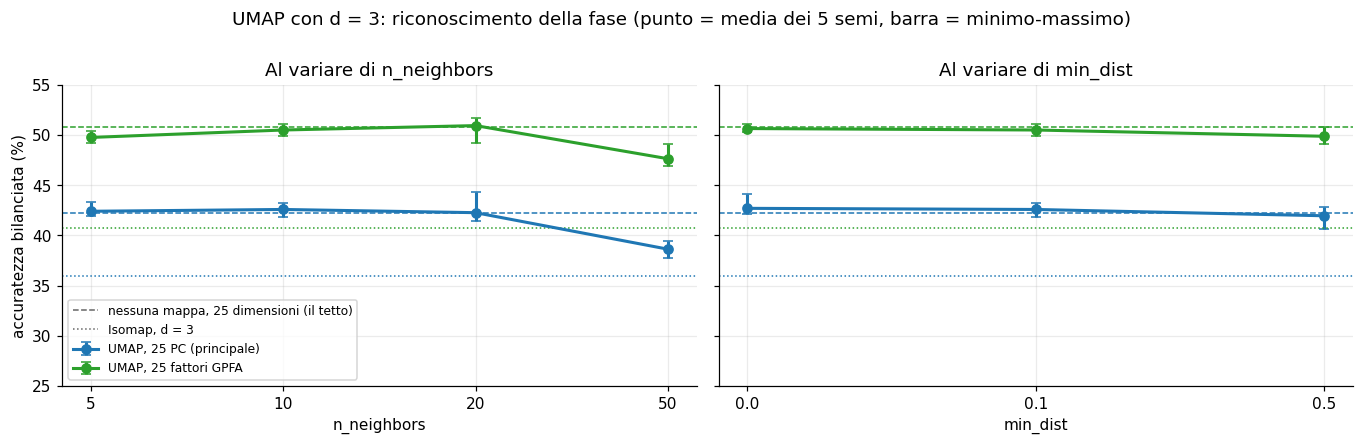

In [34]:
NN_LIST = (5, 10, 20, 50)                                   # n_neighbors: quanto è grande il "vicinato" di ogni punto
MD_LIST = (0.0, 0.1, 0.5)                                   # min_dist: quanto i punti possono ammassarsi nella mappa

sens = {}                                                   # (input, parametro, valore) -> le 5 accuratezze, una per seme
for name in INPUTS_U:
    for nn in NN_LIST:
        sens[(name, "n_neighbors", nn)] = umap_seeds(name, d=D_EVAL, n_neighbors=nn)
    for md in MD_LIST:
        sens[(name, "min_dist", md)] = umap_seeds(name, d=D_EVAL, min_dist=md)
tab_sens = pd.DataFrame({(n_, p_, str(v_)): {"media": a_.mean(), "minimo": a_.min(), "massimo": a_.max()}
                         for (n_, p_, v_), a_ in sens.items()}).T
display(tab_sens.round(1))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4), sharey=True)
for a_, (par, vals) in zip(ax, (("n_neighbors", NN_LIST), ("min_dist", MD_LIST))):
    for name, c_ in zip(INPUTS_U, ("C0", "C2")):
        A = np.array([sens[(name, par, v)] for v in vals])  # (valori del parametro, 5 semi)
        a_.errorbar(range(len(vals)), A.mean(1), yerr=[A.mean(1) - A.min(1), A.max(1) - A.mean(1)], fmt="o-",
                    color=c_, lw=2, capsize=3, label=f"UMAP, {name}")
        a_.axhline(float(tab_u.loc["nessuna mappa, 25 dimensioni (il tetto)", name]), color=c_, ls="--", lw=1)
        a_.axhline(float(tab_u.loc[f"Isomap, d = {D_EVAL}", name]), color=c_, ls=":", lw=1)
    a_.set(xticks=range(len(vals)), xticklabels=vals, xlabel=par, title=f"Al variare di {par}")
ax[0].set_ylabel("accuratezza bilanciata (%)")
ax[0].plot([], [], color="0.4", ls="--", lw=1, label="nessuna mappa, 25 dimensioni (il tetto)")
ax[0].plot([], [], color="0.4", ls=":", lw=1, label=f"Isomap, d = {D_EVAL}")
ax[0].legend(fontsize=8, loc="lower left"); ax[0].set_ylim(25, 55)
fig.suptitle(f"UMAP con d = {D_EVAL}: riconoscimento della fase (punto = media dei 5 semi, barra = minimo-massimo)", y=1.0)
fig.tight_layout(); fig.savefig(FIGS / "03_umap_sensitivity.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Con `n_neighbors` da 5 a 20 il risultato non cambia**: 42.3-42.6% sui 25 PC, 49.7-50.9% sui
  fattori GPFA, sempre al livello del tetto.
- **Con 50 vicini scende** (38.6% e 47.6%): con un vicinato largo UMAP guarda meno localmente e
  perde una parte dell'informazione. Resta comunque sopra Isomap con d = 3 (36.0% e 40.7%).
- **`min_dist` non conta** per questa misura (41.9-42.7% e 49.9-50.6%): cambia l'aspetto della
  mappa, non chi è vicino a chi.
- **Tra i semi** ci sono al massimo 3 punti di differenza (di solito 1-2).

Al §7.1 il vantaggio di Isomap dipendeva da k ed era piccolo. Quello di UMAP nel riconoscere le
fasi con 2-3 coordinate è **grande e stabile**, purché il vicinato resti piccolo.

### 9.4 · Le traiettorie single-trial

La stessa misura del §6.1: le 119 finestre da 1 s proiettate nella mappa a 3 dimensioni con
`transform`, poi seghettatura e consistenza.

In [35]:
u3 = UMAP(n_neighbors=K_NN, n_components=3, random_state=0, n_jobs=1).fit(X)  # UMAP a 3 dimensioni sugli stessi punti del §4
traj["UMAP"] = np.split(u3.transform(np.concatenate(win_X)), len(win_X))      # le 119 finestre da 1 s, proiettate con transform
tab_traj_u = pd.DataFrame([{"metodo": m, "seghettatura (più bassa = meglio)": roughness([t_[:, :3] for t_ in traj[m]]),
                            "consistenza (più alta = meglio)": consistency([t_[:, :3] for t_ in traj[m]])}
                           for m in ("PCA", "Isomap", "UMAP")]).set_index("metodo")
display(tab_traj_u.round(4))

,seghettatura (più bassa = meglio),consistenza (più alta = meglio)
metodo,,
PCA,0.0126,0.0879
Isomap,0.2747,0.0951
UMAP,0.5912,0.1290


**Lettura.**

- **Seghettatura ancora più alta**: 0.59 contro 0.27 di Isomap e 0.013 della PCA. Anche
  `transform` di UMAP lavora a vicini, e il punto salta quando i vicini cambiano.
- **Consistenza più alta** (0.13 contro 0.095 e 0.088, con un solo seme): nelle coordinate di UMAP
  le ripetizioni della stessa fase hanno un andamento nel tempo un po' più simile. La misura
  mescola però le due versioni del task (§9.2).
- Vale il limite del §6.1: UMAP dà una mappa, non un modello dei dati. Per le traiettorie
  single-trial il riferimento resta la GPFA: consistenza simile (0.11), ma seghettatura circa 50
  volte più bassa (0.011 contro 0.59).

### 9.5 · Riepilogo di UMAP

| che cosa | valori provati | effetto | dove |
|---|---|---|---|
| riconoscimento delle fasi, d = 3 | UMAP, Isomap, PCA, nessuna mappa; 25 PC e fattori GPFA | UMAP 42.6% e 50.5%, al livello del tetto (42.2% e 50.8%); Isomap 36.0% e 40.7%; PCA 32.4% e 30.5% | §9.1 |
| tetto a parità di punti | 25 PC sugli 872 punti dei fattori GPFA | 43.0%, contro 50.8% dei fattori GPFA | §9.1 |
| input di UMAP | conteggi grezzi, smussati senza PCA, 25 PC, fattori GPFA | 17.0%, 40.2%, 42.6%, 50.5%, sempre al livello del riferimento senza mappa | §9.1 |
| gemelli senza curvatura, mappe | 5 gemelli dei 25 PC e 1 dei fattori GPFA, un seme | nessuna isola in nessuno dei 6 | §9.2 |
| gemelli senza curvatura, vicini conservati | 5 gemelli; 5 semi sui dati | UMAP circa 3 volte la PCA sia sui dati sia sui gemelli; UMAP − PCA con d = 3: 26.6 punti sui dati, 22.8 sui gemelli | §9.2 |
| vicini conservati al variare della scala | k = 5-200 (k della misura; quello del metodo resta 10) | UMAP − PCA sui dati: +30.7 punti con k = 5, +0.5 con k = 200; dati − gemelli massimo a scala intermedia (k = 20-50: UMAP +9.3, Isomap +5.6, PCA +3.1), minore con k = 5 e con k = 200 | §9.2 |
| le due isole di `Shape` | divisione in 2 gruppi vs trial dispari e pari | coincidono: UMAP e Isomap 98-100%, PCA 79-88% (a caso 59%) | §9.2 |
| semi | 5 | 1-3 punti tra il migliore e il peggiore | §9.1, §9.3 |
| `n_neighbors` | 5, 10, 20, 50 | stabile fino a 20, scende a 50 (38.6% e 47.6%) | §9.3 |
| `min_dist` | 0, 0.1, 0.5 | nessun effetto sulla misura | §9.3 |
| traiettorie single-trial | PCA, Isomap, UMAP | seghettatura 0.013, 0.27, 0.59 | §9.4 |

**Che cosa abbiamo imparato su UMAP**

1. **Tra i tre metodi provati, UMAP è quello che conserva meglio in 2-3 coordinate l'informazione
   sulle fasi.** Riconosce le fasi quanto il classificatore sulle 25 dimensioni, molto meglio di
   Isomap e della PCA, e il risultato cambia poco con il seme, con `min_dist` e con `n_neighbors`
   tra 5 e 20 (con 50 scende di 3-4 punti). È una buona mappa per vedere quali fasi si separano,
   non per leggere distanze, grandezza dei gruppi o traiettorie.
2. **Non aggiunge informazione.** Resta al livello del tetto, poco sopra o poco sotto a seconda del
   seme: quello che mostra era già nei vicini.
3. **È coerente con l'ipotesi del §7.2 solo in parte, e non la dimostra.** L'informazione sulle
   fasi sta nei vicinati in 25 dimensioni (il tetto si raggiunge senza nessuna mappa) e UMAP, che
   conserva i vicinati, la porta in 2-3 coordinate; Isomap e la PCA ne perdono una parte. Ma UMAP
   conserva i vicinati quasi altrettanto bene su un gemello piatto: la sua riuscita non dimostra né
   che la struttura sia non lineare né che il manifold sia curvo. E al variare della scala (§9.2)
   "locale" va precisato: la struttura in più dei gemelli è massima in vicinati di 20-50 punti
   (UMAP +9.3 punti con k = 50, +2.0 con k = 5), non tra i vicinissimi, e si riduce alla scala più
   grande. L'abbiamo misurato solo sui 25 PC.
4. **Le isole non nascono dal metodo applicato a una nuvola gaussiana**: sui gemelli non
   compaiono. Per `Shape` corrispondono a una differenza reale nel task (le due versioni, trial
   dispari e pari); per `Grasp` e `Release` no: la loro divisione in due gruppi non segue le due
   versioni (52-67%, entro il caso).
5. **Le ripetizioni di una fase non sono repliche**: il task alterna due versioni tra trial dispari
   e pari. Riguarda anche le medie per fase e la consistenza dei notebook precedenti.
6. **Limiti**: le distanze nella mappa non si interpretano, non c'è una stima della dimensione,
   le traiettorie sono le più seghettate di tutte.

> **Regola per la tesi.** UMAP si usa per **mostrare**, non per **misurare** la forma del manifold.
> Un risultato va riportato con il suo tetto e con il gemello, per esempio: *"UMAP (n_neighbors =
> 10, min_dist = 0.1, 5 semi) su 25 PC dei firing rate smussati (σ = 50 ms), un punto ogni 100 ms
> nelle fasi di movimento: accuratezza bilanciata nel riconoscere la fase con 3 coordinate 42.6%
> (41.9-43.2 tra i semi), contro 42.2% del classificatore sulle 25 dimensioni e 32.4% della PCA con
> 3 componenti; su 5 surrogati a fasi casuali la mappa non mostra gruppi"*.

## Riferimenti

- Tenenbaum, J. B., de Silva, V., Langford, J. C. (2000). A global geometric framework for
  nonlinear dimensionality reduction. *Science*, 290(5500), 2319–2323.
- Jazayeri, M., Ostojic, S. (2021). Interpreting neural computations by examining intrinsic and
  embedding dimensionality of neural activity. *Current Opinion in Neurobiology*, 70, 113–120.
- Theiler, J. (1986). Spurious dimension from correlation algorithms applied to limited
  time-series data. *Physical Review A*, 34(3), 2427–2432.
- Theiler, J., Eubank, S., Longtin, A., Galdrikian, B., Farmer, J. D. (1992). Testing for
  nonlinearity in time series: the method of surrogate data. *Physica D*, 58, 77–94.
- Prichard, D., Theiler, J. (1994). Generating surrogate data for time series with several
  simultaneously measured variables. *Physical Review Letters*, 73(7), 951–954.
- Schreiber, T., Schmitz, A. (1996). Improved surrogate data for nonlinearity tests. *Physical
  Review Letters*, 77(4), 635–638.
- Facco, E., d'Errico, M., Rodriguez, A., Laio, A. (2017). Estimating the intrinsic dimension of
  datasets by a minimal neighborhood information. *Scientific Reports*, 7, 12140.
- Yu, B. M., et al. (2009). Gaussian-process factor analysis for low-dimensional single-trial
  analysis of neural population activity. *Journal of Neurophysiology*, 102, 614–635.
- McInnes, L., Healy, J., Melville, J. (2018). UMAP: Uniform Manifold Approximation and Projection
  for dimension reduction. *arXiv*:1802.03426.
- Chari, T., Pachter, L. (2023). The specious art of single-cell genomics. *PLoS Computational
  Biology*, 19(8), e1011288.